<a href="https://colab.research.google.com/github/AmyMugeni/Simulens/blob/main/Simulens_ML_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simulens system
 A machine learning model to predict user social media behaviour, Identify progressive compulsive social media use and deliver intervention prompts and educational insights against such use.

The model draws on contextual information provided by the user such as BSMAS score, weekly schedule and circardian rhythm.
By the use of Android APIs, the ML model uses session frequency, screen time, most app used, schedule conflicts, time of usage, session duration and session gaps to determine whether a session is intentional or not.

The model derives an average baseline from each user and monitores both + and - derivations and applies contextual information to deliver interventions.

# 1: Mounting Google Drive

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

project_path = '/content/drive/MyDrive/Cognilens_MLtraining'
os.makedirs(project_path, exist_ok=True)
os.chdir(project_path)

print(f"Working directory set to: {os.getcwd()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory set to: /content/drive/MyDrive/Cognilens_MLtraining


## 2: Imports and Setup

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import classification_report, roc_auc_score, f1_score
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier


## 2. Data Loading and Initial Cleaning

In [ ]:
import glob
import pandas as pd

# Find all files starting with 'SocialMediaUse'
file_pattern = 'SocialMediaUse*'
files = glob.glob(file_pattern)
print(f"Found {len(files)} files: {files}")

# Load and concatenate all matching CSV files
data_list = []
for file in files:
    try:
        df_temp = pd.read_csv(file)
        data_list.append(df_temp)
        print(f"Successfully loaded {file} with shape {df_temp.shape}")
    except Exception as e:
        print(f"Error loading {file}: {e}")

if data_list:
    df = pd.concat(data_list, ignore_index=True)
    print(f"Combined DataFrame shape: {df.shape}")

    # Columns specified for removal
    cols_to_drop = [
        'notification_count', 'triggered_by_notification',
        'scroll_count', 'scroll_speed_estimate', 'avg_scroll_delta_px',
        'micro_scrolls', 'normal_scrolls', 'macro_scrolls',
        'scroll_behavior', 'detected_format'
    ]

    # Drop columns that actually exist in the DataFrame
    existing_cols_to_drop = [col for col in cols_to_drop if col in df.columns]
    df = df.drop(columns=existing_cols_to_drop)
    print(f"Dropped {len(existing_cols_to_drop)} columns. New shape: {df.shape}")

    display(df.head())
    df.info()
else:
    print("No matching files found. Please ensure files starting with 'SocialMediaUse' exist in your Google Drive folder.")

Found 18 files: ['SocialMediaUse_export (4).csv', 'SocialMediaUse_export (2).csv', 'SocialMediaUse_export (3).csv', 'SocialMediaUse_export (1).csv', 'SocialMediaUse_export 5.csv', 'SocialMediaUse_export 6.csv', 'SocialMediaUse_export.csv', 'SocialMediaUse_export 7.csv', 'SocialMediaUse_export 8.csv', 'SocialMediaUse_export 9.csv', 'SocialMediaUse_export 10.csv', 'SocialMediaUse_export 11.csv', 'SocialMediaUse_export 15.csv', 'SocialMediaUse_export 14.csv', 'SocialMediaUse_export 13.csv', 'SocialMediaUse_export 16.csv', 'SocialMediaUse_export 17.csv', 'SocialMediaUse_export 19.csv']
Successfully loaded SocialMediaUse_export (4).csv with shape (502, 26)
Successfully loaded SocialMediaUse_export (2).csv with shape (708, 26)
Successfully loaded SocialMediaUse_export (3).csv with shape (171, 26)
Successfully loaded SocialMediaUse_export (1).csv with shape (645, 26)
Successfully loaded SocialMediaUse_export 5.csv with shape (183, 26)
Successfully loaded SocialMediaUse_export 6.csv with shape

,user_id,session_start,session_end,date,day_of_week,session_hour,time_of_day,app_label,duration_minutes,tap_count,minutes_since_last_session,day_asi_score,day_intensity_score,day_fragmentation_score,day_compulsion_score,day_disruption_score
0,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790281329502,1790281593063,2026-09-24,Thursday,23,night,Instagram,4.39,0,28.47,48,45,68,32,49
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790279631154,1790279723216,2026-09-24,Thursday,22,night,YouTube,1.53,0,33.34,48,45,68,32,49
2,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790279484659,1790279621543,2026-09-24,Thursday,22,night,Instagram,2.28,0,7.95,48,45,68,32,49
3,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790278804601,1790279007621,2026-09-24,Thursday,22,night,Instagram,3.38,2,2.64,48,45,68,32,49
4,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,1790278538451,1790278646464,2026-09-24,Thursday,22,night,Instagram,1.80,0,0.00,48,45,68,32,49


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15893 entries, 0 to 15892
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   user_id                     15893 non-null  object 
 1   session_start               15893 non-null  int64  
 2   session_end                 15893 non-null  int64  
 3   date                        15893 non-null  object 
 4   day_of_week                 15893 non-null  object 
 5   session_hour                15893 non-null  int64  
 6   time_of_day                 15893 non-null  object 
 7   app_label                   15893 non-null  object 
 8   duration_minutes            15893 non-null  float64
 9   tap_count                   15893 non-null  int64  
 10  minutes_since_last_session  15832 non-null  float64
 11  day_asi_score               15893 non-null  int64  
 12  day_intensity_score         15893 non-null  int64  
 13  day_fragmentation_score     158

### 3. Data Inspection, Duplicates, and Overlapping Sessions
In this step, we will check for identical row duplicates and identify sessions for individual users that overlap in time (where a session starts before the previous one ends).

In [ ]:
# 1. Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"Total exact duplicate rows: {duplicate_rows}")

# 2. Check for overlapping sessions per user
# Sort by user and session start time
df_sorted = df.sort_values(by=['user_id', 'session_start']).copy()

# Identify overlaps: a session overlaps if its start time is strictly less than the previous session's end time for the same user
df_sorted['prev_session_end'] = df_sorted.groupby('user_id')['session_end'].shift(1)
df_sorted['is_overlapping'] = df_sorted['session_start'] < df_sorted['prev_session_end']

overlapping_count = df_sorted['is_overlapping'].sum()
print(f"Total overlapping sessions detected: {overlapping_count}")

if overlapping_count > 0:
    print("\nExample of overlapping sessions:")
    overlapping_examples = df_sorted[df_sorted['is_overlapping'] | df_sorted['is_overlapping'].shift(-1)]
    display(overlapping_examples[['user_id', 'session_start', 'session_end', 'app_label', 'duration_minutes']].head(10))
else:
    print("No overlapping sessions found.")

Total exact duplicate rows: 4945
Total overlapping sessions detected: 5844

Example of overlapping sessions:


,user_id,session_start,session_end,app_label,duration_minutes
8159,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968227560,1790968263875,Instagram,0.61
12891,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968227560,1790968263875,Instagram,0.61
8158,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968452965,1790968495206,Instagram,0.70
12890,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968452965,1790968495206,Instagram,0.70
8157,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790970958366,1790971000345,Instagram,0.70
12889,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790970958366,1790971000345,Instagram,0.70
8156,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971020285,1790971119437,Instagram,1.65
12888,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971020285,1790971119437,Instagram,1.65
8155,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971774656,1790971815631,Instagram,0.68
12887,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971774656,1790971815631,Instagram,0.68


### 4. Cleaning Duplicates and Re-evaluating Session Overlaps
Now we will clean up the dataset by removing exact duplicate rows first, then re-assess if there are any genuine temporal overlaps between distinct sessions.

In [ ]:
# 1. Remove exact duplicate rows from the master dataframe
print(f"Shape before dropping duplicates: {df.shape}")
df = df.drop_duplicates()
print(f"Shape after dropping duplicates: {df.shape}")

# 2. Re-evaluate overlapping sessions on the cleaned dataset
df_sorted_clean = df.sort_values(by=['user_id', 'session_start']).copy()
df_sorted_clean['prev_session_end'] = df_sorted_clean.groupby('user_id')['session_end'].shift(1)
df_sorted_clean['is_overlapping'] = df_sorted_clean['session_start'] < df_sorted_clean['prev_session_end']

remaining_overlaps = df_sorted_clean['is_overlapping'].sum()
print(f"\nRemaining overlapping sessions after duplicate removal: {remaining_overlaps}")

if remaining_overlaps > 0:
    print("\nExamples of genuine overlapping sessions:")
    overlap_examples = df_sorted_clean[df_sorted_clean['is_overlapping'] | df_sorted_clean['is_overlapping'].shift(-1)]
    display(overlap_examples[['user_id', 'session_start', 'session_end', 'app_label', 'duration_minutes']].head(10))
else:
    print("No overlapping sessions remain!")

Shape before dropping duplicates: (15893, 16)
Shape after dropping duplicates: (10948, 16)

Remaining overlapping sessions after duplicate removal: 899

Examples of genuine overlapping sessions:


,user_id,session_start,session_end,app_label,duration_minutes
7740,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752536039,1791752567392,Instagram,0.52
12472,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752536039,1791752567392,Instagram,0.52
7739,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752691989,1791752745364,Instagram,0.89
12471,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752691989,1791752745364,Instagram,0.89
7738,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752786962,1791753007190,Instagram,3.67
12470,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791752786962,1791753007190,Instagram,3.67
7737,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753012767,1791753050861,Instagram,0.63
12469,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753012767,1791753050861,Instagram,0.63
7736,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753102302,1791753409240,Instagram,5.12
12468,195f6f81-23c7-4fc7-88dd-2906f500aee9,1791753102302,1791753409240,Instagram,5.12


### 5. Deduplicating based on Unique Session Keys
Some sessions represent the exact same event but might differ slightly in computed fields. We will deduplicate based on `['user_id', 'session_start', 'session_end']` to ensure absolute uniqueness per session event.

In [ ]:
# 1. Drop duplicates based on the primary session keys
print(f"Shape before session-key deduplication: {df.shape}")
df = df.drop_duplicates(subset=['user_id', 'session_start', 'session_end'])
print(f"Shape after session-key deduplication: {df.shape}")

# 2. Re-calculate genuine overlaps
df_sorted_clean = df.sort_values(by=['user_id', 'session_start']).copy()
df_sorted_clean['prev_session_end'] = df_sorted_clean.groupby('user_id')['session_end'].shift(1)
df_sorted_clean['is_overlapping'] = df_sorted_clean['session_start'] < df_sorted_clean['prev_session_end']

genuine_overlaps = df_sorted_clean['is_overlapping'].sum()
print(f"\nGenuine overlapping sessions remaining: {genuine_overlaps}")

if genuine_overlaps > 0:
    print("\nExamples of actual overlapping sessions (where start < previous end):")
    overlap_examples = df_sorted_clean[df_sorted_clean['is_overlapping'] | df_sorted_clean['is_overlapping'].shift(-1)]
    display(overlap_examples[['user_id', 'session_start', 'session_end', 'app_label', 'duration_minutes']].head(10))
else:
    print("No overlapping sessions remain!")

Shape before session-key deduplication: (10948, 16)
Shape after session-key deduplication: (10295, 16)

Genuine overlapping sessions remaining: 246

Examples of actual overlapping sessions (where start < previous end):


,user_id,session_start,session_end,app_label,duration_minutes
915,85bfc215-c24f-4814-aa00-6794f1a7278a,1777835435588,1777835574043,Instagram,2.31
914,85bfc215-c24f-4814-aa00-6794f1a7278a,1777835498000,1777835530000,Instagram,0.53
911,85bfc215-c24f-4814-aa00-6794f1a7278a,1777836062457,1777838251607,Instagram,36.49
910,85bfc215-c24f-4814-aa00-6794f1a7278a,1777836222000,1777836271000,Instagram,0.82
902,85bfc215-c24f-4814-aa00-6794f1a7278a,1777865312196,1777865460460,Instagram,2.47
901,85bfc215-c24f-4814-aa00-6794f1a7278a,1777865454000,1777888271000,Instagram,380.28
884,85bfc215-c24f-4814-aa00-6794f1a7278a,1778008246942,1778008931441,Instagram,11.41
883,85bfc215-c24f-4814-aa00-6794f1a7278a,1778008342000,1778008404000,Instagram,1.03
878,85bfc215-c24f-4814-aa00-6794f1a7278a,1778009684514,1778009855102,Instagram,2.84
877,85bfc215-c24f-4814-aa00-6794f1a7278a,1778009847000,1778012017000,Instagram,36.17


### 6. Merging Overlapping Sessions
We will group the data by `user_id` and merge chronologically overlapping sessions into single unified sessions, recalculating timestamps and session durations.

In [ ]:
def merge_user_sessions(group):
    # Sort the group by session_start
    group = group.sort_values('session_start')

    merged = []
    for _, row in group.iterrows():
        if not merged:
            merged.append(row.to_dict())
        else:
            prev = merged[-1]
            # Overlap condition: current start <= previous end
            if row['session_start'] <= prev['session_end']:
                # Merge by extending the end time of the previous session if needed
                prev['session_end'] = max(prev['session_end'], row['session_end'])
                # Accumulate quantitative values
                prev['tap_count'] += row['tap_count']
                # Re-calculate duration based on the new interval
                # Timestamps are in milliseconds, duration_minutes = ms / 60000
                prev['duration_minutes'] = round((prev['session_end'] - prev['session_start']) / 60000.0, 2)
            else:
                merged.append(row.to_dict())

    return pd.DataFrame(merged)

print(f"Original shape before merging: {df.shape}")

# Group by user and apply the merge algorithm
df_merged = df.groupby('user_id', as_index=False, group_keys=False).apply(merge_user_sessions)

print(f"New shape after merging overlapping sessions: {df_merged.shape}")

# Update our master dataframe variable
df = df_merged.reset_index(drop=True)

# Re-verify if any overlapping sessions remain
df_sorted_clean = df.sort_values(by=['user_id', 'session_start']).copy()
df_sorted_clean['prev_session_end'] = df_sorted_clean.groupby('user_id')['session_end'].shift(1)
df_sorted_clean['is_overlapping'] = df_sorted_clean['session_start'] < df_sorted_clean['prev_session_end']

print(f"Overlapping sessions remaining: {df_sorted_clean['is_overlapping'].sum()}")
display(df.head())

Original shape before merging: (10295, 16)
New shape after merging overlapping sessions: (10025, 16)
Overlapping sessions remaining: 0


/tmp/ipykernel_1752/725456277.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_merged = df.groupby('user_id', as_index=False, group_keys=False).apply(merge_user_sessions)


,user_id,session_start,session_end,date,day_of_week,session_hour,time_of_day,app_label,duration_minutes,tap_count,minutes_since_last_session,day_asi_score,day_intensity_score,day_fragmentation_score,day_compulsion_score,day_disruption_score
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968227560,1790968263875,2026-10-02,Friday,22,night,Instagram,0.61,0,NaN,38,4,41,57,60
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790968452965,1790968495206,2026-10-02,Friday,22,night,Instagram,0.70,0,3.15,38,4,41,57,60
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790970958366,1790971000345,2026-10-02,Friday,22,night,Instagram,0.70,0,41.05,38,4,41,57,60
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971020285,1790971119437,2026-10-02,Friday,22,night,Instagram,1.65,0,0.33,38,4,41,57,60
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,1790971774656,1790971815631,2026-10-02,Friday,23,night,Instagram,0.68,0,10.92,38,4,41,57,60


### 7. Load and Inspect Timetable Datasets
We will scan the directory to find the timetable files (`final_timetable.csv` and the other Excel/CSV starting with `bics_4a_apr_July`), load them to inspect their columns, and prepare them for mapping.

In [ ]:
import os
import glob
import pandas as pd

# Find timetable files
timetable_files = glob.glob('*timetable*') + glob.glob('*bics*')
print("Found files matching timetable patterns:", timetable_files)

# Let's inspect the files found
for file in timetable_files:
    try:
        if file.endswith('.csv'):
            temp_df = pd.read_csv(file)
        else:
            temp_df = pd.read_excel(file)
        print(f"\nFile: {file} | Shape: {temp_df.shape}")
        print("Columns:", temp_df.columns.tolist())
        display(temp_df.head(3))
    except Exception as e:
        print(f"Error reading {file}: {e}")

Found files matching timetable patterns: ['final_timetable.csv', 'bics_4a_apr_jul_2026.csv']

File: final_timetable.csv | Shape: (5, 10)
Columns: ['Day', '8.15 - 9.15', '9.15 – 10.15', '10.15 – 11.15', '11.15 – 12.15', '12.15 - 1.15', '1.15 - 2.15', '2.15 – 3.15', '3.15 – 4.15', '4.15 - 5.15']


,Day,8.15 - 9.15,9.15 – 10.15,10.15 – 11.15,11.15 – 12.15,12.15 - 1.15,1.15 - 2.15,2.15 – 3.15,3.15 – 4.15,4.15 - 5.15
0,Monday,ICS | Computing and | LT,4212 | Business Law | 1,-,Maisha Program 8 | Ladies STM B B 03,ICS | Computer | Meeting ID: 374 | Passcode:,3205 | Graphic | 798 961 774 348 | wq9BT73M,-,ICS | ICS | MSB,4101 | Project II | 4
1,Tuesday,G Wasonga | ICS | ICS Project | Meeting ID: 33...,4101 | II | 292 383 153 21 | my74JL7a,ICS 4212 | Computing and | Business Law | Meet...,R Bunde,Z | ICS 4201 | Compiler | LT,Muti | Construction | 6,ICS | Information Systems | LT,K | 4203 | Security and Design | 3,Omondi
2,Wednesday,K Omondi,ICS | Compiler | Meeting ID: | Passcode:,G Wasonga | 4201 | Construction | 352 281 059 ...,ICS 4212 | Corporate Governance | and Sustaina...,K,Ouma | ICS | Information Systems | Meeting ID:...,J | 4203 | Security and Design | 664 371 574 5...,Mutahi,ICS 4301 | Computing for | Bioinformatics | Me...



File: bics_4a_apr_jul_2026.csv | Shape: (17, 4)
Columns: ['day', 'start_time', 'end_time', 'activity']


,day,start_time,end_time,activity
0,Monday,08:15,10:15,ICS 4106 - Computer Simulation and Modelling
1,Monday,10:15,12:15,ICS 4102 - Machine Learning
2,Monday,13:15,14:15,ICS 4103 - Cloud Computing


### 8. Normalize Timetables and Map Schedule Conflicts
We will combine the schedules from `final_timetable.csv` and `bics_4a_apr_jul_2026.csv` into a clean, standardized format. Then, we will map each social media session to determine if it overlaps with any scheduled class or activity slot.

In [ ]:
import datetime

# 1. Parse 'bics_4a_apr_jul_2026.csv'
bics_df = pd.read_csv('bics_4a_apr_jul_2026.csv')
schedule_list = []

# Clean weekday names to standard capitalized forms
def clean_day(day_str):
    return str(day_str).strip().capitalize()

for _, row in bics_df.iterrows():
    day = clean_day(row['day'])
    start_time = row['start_time'].strip()
    end_time = row['end_time'].strip()
    activity = str(row['activity']).strip()
    # Avoid adding entries that are free/sports/empty if they do not represent a conflict
    if activity and activity != '-' and 'free' not in activity.lower():
        schedule_list.append({
            'day': day,
            'start_time': start_time,
            'end_time': end_time,
            'activity': activity
        })

# 2. Parse 'final_timetable.csv' (Wide Format)
final_tt_df = pd.read_csv('final_timetable.csv')
time_cols = [c for c in final_tt_df.columns if c != 'Day']

# Helper to standardize dash and spaces in times
def parse_time_range(col_name):
    # Replaces varied dashes with standard hyphen
    col_cleaned = col_name.replace('–', '-').replace(' ', '')
    start, end = col_cleaned.split('-')
    # Standardize to HH:MM
    def format_hm(t_str):
        parts = t_str.split('.')
        h = int(parts[0])
        m = int(parts[1]) if len(parts) > 1 else 0
        # Standardize 12-hour values after 8.15 to PM if they are smaller than 8 (e.g. 1.15 -> 13:15)
        if h < 8:
            h += 12
        return f"{h:02d}:{m:02d}"
    return format_hm(start), format_hm(end)

for _, row in final_tt_df.iterrows():
    day = clean_day(row['Day'])
    for col in time_cols:
        cell_val = str(row[col]).strip()
        if cell_val and cell_val != '-' and cell_val.lower() != 'nan':
            try:
                start_t, end_t = parse_time_range(col)
                schedule_list.append({
                    'day': day,
                    'start_time': start_t,
                    'end_time': end_t,
                    'activity': cell_val
                })
            except Exception as e:
                print(f"Skipping cell parse due to error: {e} in column {col}")

schedules_df = pd.DataFrame(schedule_list)
print(f"Normalized schedules: {schedules_df.shape[0]} slots active.")
display(schedules_df.head(10))

# 3. Define function to check schedule conflicts
def has_conflict(row):
    # Extract day and time
    # session_start is in milliseconds. Convert to datetime
    session_dt = datetime.datetime.fromtimestamp(row['session_start'] / 1000.0, tz=datetime.timezone.utc)
    day_name = session_dt.strftime('%A')
    session_time_str = session_dt.strftime('%H:%M')

    # Check matching day in schedule
    day_schedules = schedules_df[schedules_df['day'] == day_name]
    for _, sched in day_schedules.iterrows():
        if sched['start_time'] <= session_time_str <= sched['end_time']:
            return 1
    return 0

# Map schedule conflicts
print("Mapping schedule conflicts onto session data...")
df['schedule_conflict'] = df.apply(has_conflict, axis=1)

print("Distribution of schedule conflicts:")
print(df['schedule_conflict'].value_counts())
display(df[['session_start', 'day_of_week', 'schedule_conflict']].head(10))

Normalized schedules: 56 slots active.


,day,start_time,end_time,activity
0,Monday,08:15,10:15,ICS 4106 - Computer Simulation and Modelling
1,Monday,10:15,12:15,ICS 4102 - Machine Learning
2,Monday,13:15,14:15,ICS 4103 - Cloud Computing
3,Monday,15:15,17:15,ICS 3105 - Multimedia Applications
4,Tuesday,08:15,10:15,ICS 4101 - ICS Project II
5,Tuesday,10:15,11:15,Maisha Program 7 - Gents 4A
6,Tuesday,11:15,12:15,Maisha Program 7 - Ladies ICS 4A
7,Tuesday,13:15,15:15,ICS 4104 - Distributed Systems
8,Wednesday,08:15,10:15,ICS 4111 - Embedded Systems and Internet of Th...
9,Wednesday,11:15,12:15,ICS 4106 - Computer Simulation and Modelling


Mapping schedule conflicts onto session data...
Distribution of schedule conflicts:
schedule_conflict
0    6562
1    3463
Name: count, dtype: int64


,session_start,day_of_week,schedule_conflict
0,1790968227560,Friday,0
1,1790968452965,Friday,0
2,1790970958366,Friday,0
3,1790971020285,Friday,0
4,1790971774656,Friday,0
5,1791010528273,Saturday,0
6,1791010622414,Saturday,0
7,1791011469356,Saturday,0
8,1791011847278,Saturday,0
9,1791012743055,Saturday,0


### 9. Configure Sleep/Wake Schedule Conflicts
We will define a global sleep schedule where the hours between midnight (00:00) and 06:00 AM are designated as sleeping hours. Any session that falls within these hours will be flagged with a schedule conflict (`schedule_conflict = 1`).

In [ ]:
import datetime

def check_sleep_and_schedule_conflict(row):
    # 1. Parse session time
    session_dt = datetime.datetime.fromtimestamp(row['session_start'] / 1000.0, tz=datetime.timezone.utc)
    day_name = session_dt.strftime('%A')
    session_time_str = session_dt.strftime('%H:%M')
    hour = session_dt.hour

    # 2. Check sleep-time conflict (12:00 AM / 00:00 to 06:00 AM)
    if 0 <= hour < 6:
        return 1

    # 3. Check existing timetable schedule conflict
    day_schedules = schedules_df[schedules_df['day'] == day_name]
    for _, sched in day_schedules.iterrows():
        if sched['start_time'] <= session_time_str <= sched['end_time']:
            return 1

    return 0

# Map the updated conflict status containing sleep times
print("Updating schedule conflicts to incorporate the 12:00 AM - 06:00 AM sleep schedule...")
df['schedule_conflict'] = df.apply(check_sleep_and_schedule_conflict, axis=1)

print("New distribution of schedule conflicts (including sleep time active sessions):")
print(df['schedule_conflict'].value_counts())
display(df[['session_start', 'session_hour', 'day_of_week', 'schedule_conflict']].head(15))

Updating schedule conflicts to incorporate the 12:00 AM - 06:00 AM sleep schedule...
New distribution of schedule conflicts (including sleep time active sessions):
schedule_conflict
0    5359
1    4666
Name: count, dtype: int64


,session_start,session_hour,day_of_week,schedule_conflict
0,1790968227560,22,Friday,0
1,1790968452965,22,Friday,0
2,1790970958366,22,Friday,0
3,1790971020285,22,Friday,0
4,1790971774656,23,Friday,0
5,1791010528273,9,Saturday,0
6,1791010622414,9,Saturday,0
7,1791011469356,10,Saturday,0
8,1791011847278,10,Saturday,0
9,1791012743055,10,Saturday,0


### 10. Data Visualization
We will visualize the session data to analyze the distributions of our key features, including the newly mapped schedule conflicts and user hourly activity patterns.

/tmp/ipykernel_1752/2886153233.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=30)


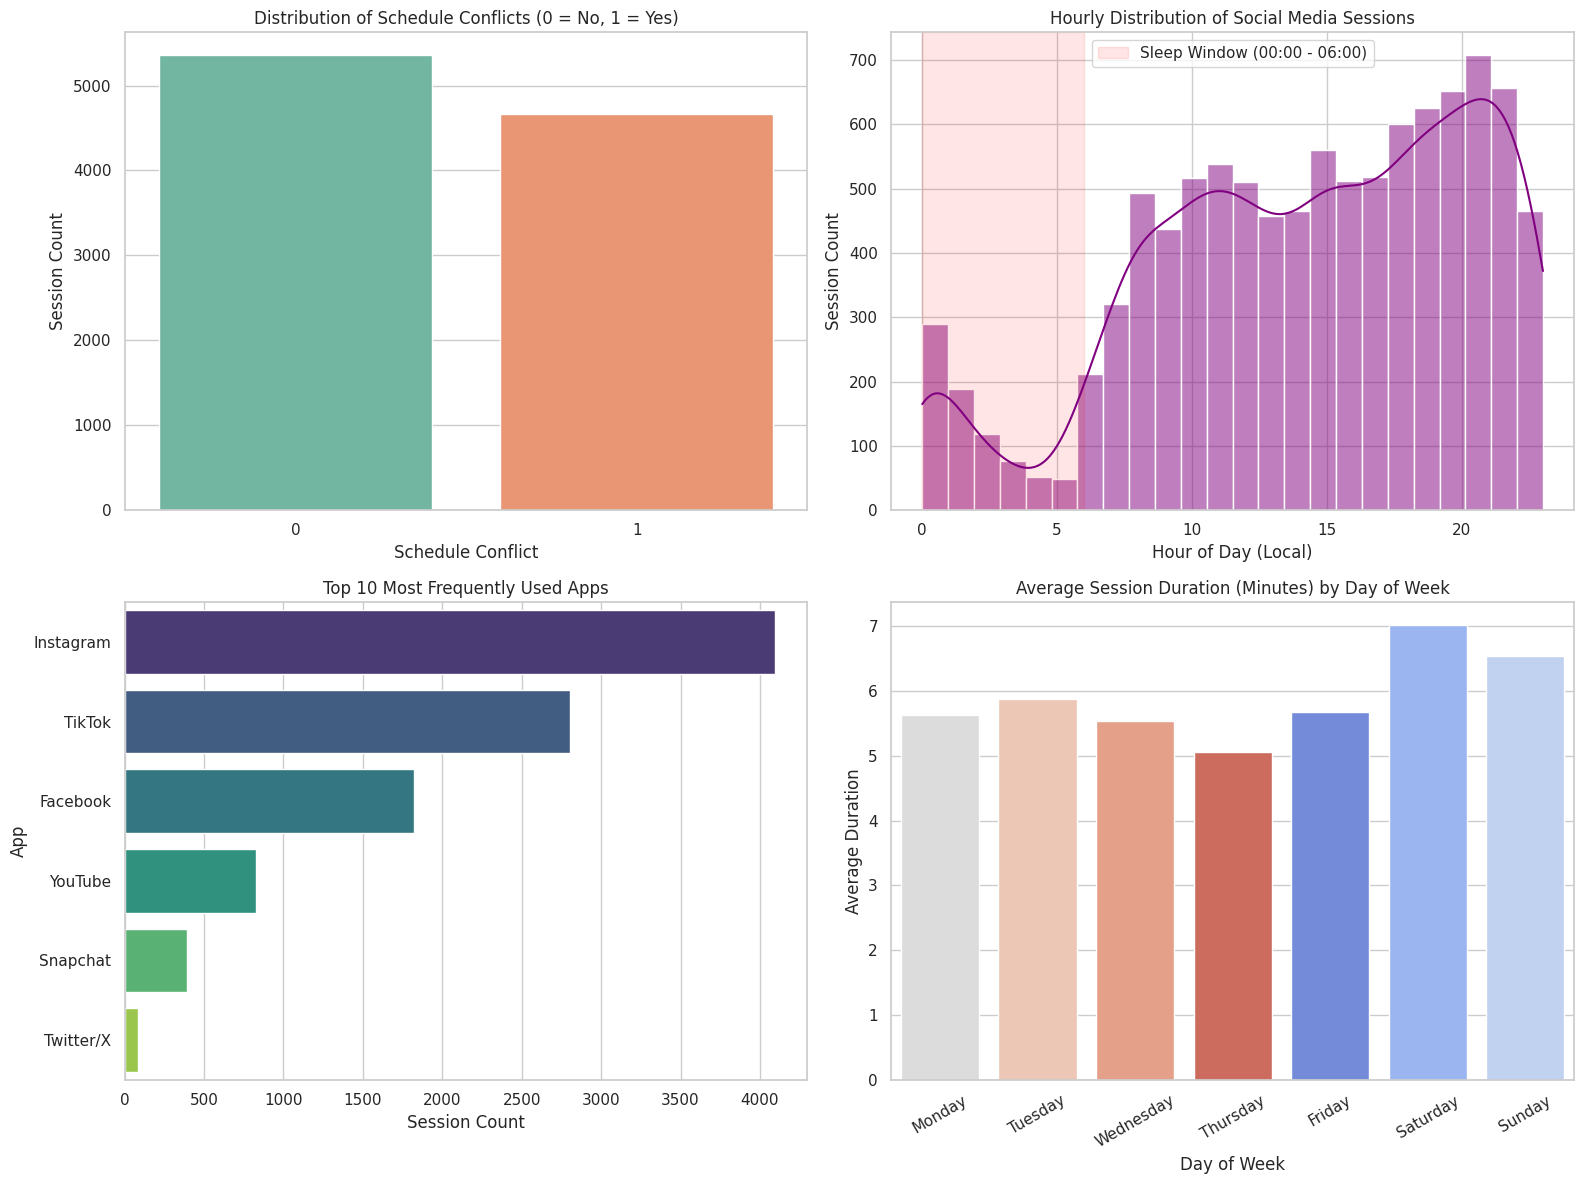

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Distribution of Schedule Conflicts
sns.countplot(ax=axes[0, 0], data=df, x='schedule_conflict', palette='Set2', hue='schedule_conflict', legend=False)
axes[0, 0].set_title('Distribution of Schedule Conflicts (0 = No, 1 = Yes)')
axes[0, 0].set_xlabel('Schedule Conflict')
axes[0, 0].set_ylabel('Session Count')

# 2. Hourly Distribution of Sessions
sns.histplot(ax=axes[0, 1], data=df, x='session_hour', bins=24, kde=True, color='purple')
axes[0, 1].set_title('Hourly Distribution of Social Media Sessions')
axes[0, 1].set_xlabel('Hour of Day (Local)')
axes[0, 1].set_ylabel('Session Count')
axes[0, 1].axvspan(0, 6, color='red', alpha=0.1, label='Sleep Window (00:00 - 06:00)')
axes[0, 1].legend()

# 3. Top Most Used Apps
top_apps = df['app_label'].value_counts().head(10)
sns.barplot(ax=axes[1, 0], x=top_apps.values, y=top_apps.index, palette='viridis', hue=top_apps.index, legend=False)
axes[1, 0].set_title('Top 10 Most Frequently Used Apps')
axes[1, 0].set_xlabel('Session Count')
axes[1, 0].set_ylabel('App')

# 4. Average Session Duration by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.barplot(ax=axes[1, 1], data=df, x='day_of_week', y='duration_minutes', order=day_order, palette='coolwarm', hue='day_of_week', legend=False, errorbar=None)
axes[1, 1].set_title('Average Session Duration (Minutes) by Day of Week')
axes[1, 1].set_xlabel('Day of Week')
axes[1, 1].set_ylabel('Average Duration')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=30)

plt.tight_layout()
plt.show()

### 11. Analyzing Average Daily Usage per User
We will group the dataset by `user_id` and `date` to find the total active duration per day, and then take the average over all days for each user.

Summary Statistics of Average Daily Social Media Usage per User (in minutes):


,avg_daily_duration_minutes
count,10.000000
mean,172.234187
std,88.018064
min,79.750000
25%,116.425125
50%,152.927530
75%,193.836349
max,372.961250


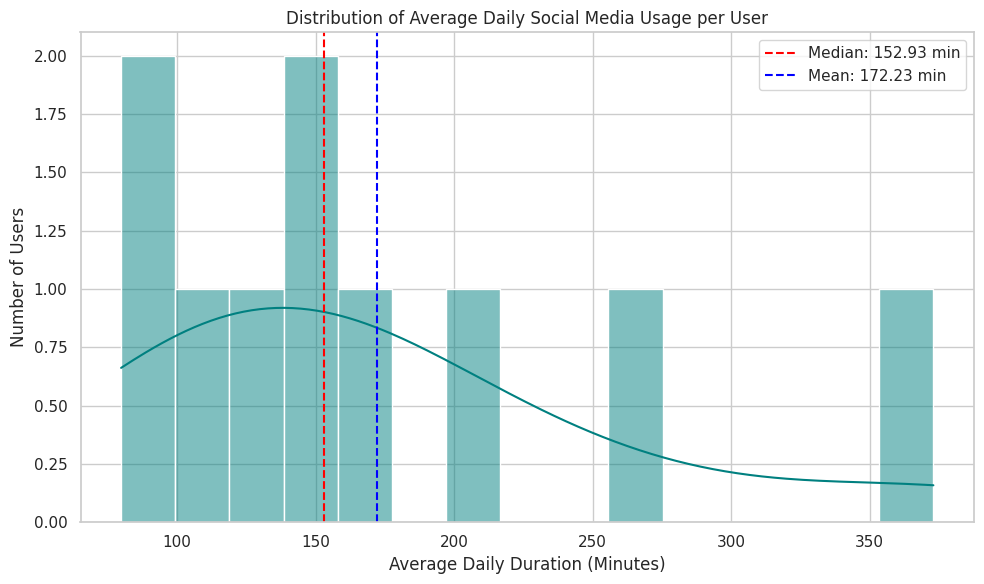

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate duration per user per day
daily_user_usage = df.groupby(['user_id', 'date'])['duration_minutes'].sum().reset_index()

# 2. Calculate the average daily usage per user
avg_daily_usage = daily_user_usage.groupby('user_id')['duration_minutes'].mean().reset_index()
avg_daily_usage.rename(columns={'duration_minutes': 'avg_daily_duration_minutes'}, inplace=True)

# Display summary statistics
print("Summary Statistics of Average Daily Social Media Usage per User (in minutes):")
display(avg_daily_usage['avg_daily_duration_minutes'].describe())

# 3. Visualize the distribution of average daily usage
plt.figure(figsize=(10, 6))
sns.histplot(data=avg_daily_usage, x='avg_daily_duration_minutes', kde=True, color='teal', bins=15)
plt.title('Distribution of Average Daily Social Media Usage per User')
plt.xlabel('Average Daily Duration (Minutes)')
plt.ylabel('Number of Users')
plt.axvline(avg_daily_usage['avg_daily_duration_minutes'].median(), color='red', linestyle='--', label=f"Median: {avg_daily_usage['avg_daily_duration_minutes'].median():.2f} min")
plt.axvline(avg_daily_usage['avg_daily_duration_minutes'].mean(), color='blue', linestyle='--', label=f"Mean: {avg_daily_usage['avg_daily_duration_minutes'].mean():.2f} min")
plt.legend()
plt.tight_layout()
plt.show()

### 16. Engineering User-Specific Baselines and Deviations

To align our model with the simulens system design, we will compute historical baseline metrics for each unique user and calculate session-by-session deviations. This shifts our model from a generic hourly classifier to a highly personalized behavioral detector.

In [ ]:

import numpy as np
import pandas as pd


def generate_personal_baselines(
    df: pd.DataFrame,
    user_col: str = "user_id",
    timestamp_col: str = "timestamp",
    duration_col: str = "duration_minutes",
    gap_col: str = "minutes_since_last_session",
    window: str = "28D",
    min_history: int = 5,
) -> pd.DataFrame:
    """
    Generate per-user, past-only rolling session baselines.

    Each session baseline uses valid observations from the
    preceding time window, excluding the current observation.

    Duration:
      duration_deviation = current duration - historical median
      duration_increase = positive duration deviation only

    Gap:
      gap_deviation = historical median gap - current gap
      gap_reduction = positive gap reduction only
    """

    required = {
        user_col, timestamp_col, duration_col, gap_col
    }
    missing = required.difference(df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if min_history < 1:
        raise ValueError("min_history must be at least 1")

    window_delta = pd.Timedelta(window)
    if window_delta <= pd.Timedelta(0):
        raise ValueError("window must be positive")

    result = df.copy().reset_index(drop=True)

    result[timestamp_col] = pd.to_datetime(
        result[timestamp_col],
        errors="coerce",
        utc=True,
    )

    for col in [duration_col, gap_col]:
        result[col] = pd.to_numeric(
            result[col], errors="coerce"
        )
        result[col] = result[col].where(
            np.isfinite(result[col]) & (result[col] >= 0)
        )

    metrics = [duration_col, gap_col]

    for col in metrics:
        result[f"{col}_baseline_median"] = np.nan
        result[f"{col}_baseline_mean"] = np.nan
        result[f"{col}_baseline_count"] = 0

    # Original row order is retained in the returned DataFrame.
    # A stable sort makes tied timestamps deterministic.
    valid = result.dropna(
        subset=[user_col, timestamp_col]
    )

    for _, group in valid.groupby(user_col, sort=False):
        group = group.sort_values(
            timestamp_col, kind="mergesort"
        )

        times = group[timestamp_col]
        indices = group.index

        for col in metrics:
            values = group[col].to_numpy(dtype=float)

            medians = np.full(len(group), np.nan)
            means = np.full(len(group), np.nan)
            counts = np.zeros(len(group), dtype=int)

            # Strictly earlier timestamps only.
            # Sessions with tied timestamps are excluded from
            # one another's baselines to avoid arbitrary ordering.
            for i, current_time in enumerate(times):
                start_time = current_time - window_delta

                historical_mask = (
                    (times < current_time)
                    & (times >= start_time)
                ).to_numpy()

                historical = values[historical_mask]
                historical = historical[
                    np.isfinite(historical)
                ]

                counts[i] = len(historical)

                if counts[i] >= min_history:
                    medians[i] = np.median(historical)
                    means[i] = np.mean(historical)

            result.loc[
                indices, f"{col}_baseline_median"
            ] = medians

            result.loc[
                indices, f"{col}_baseline_mean"
            ] = means

            result.loc[
                indices, f"{col}_baseline_count"
            ] = counts

    duration_baseline = result[
        f"{duration_col}_baseline_median"
    ]
    gap_baseline = result[
        f"{gap_col}_baseline_median"
    ]

    # Duration deviation: positive means longer than usual.
    result["duration_deviation"] = (
        result[duration_col] - duration_baseline
    )
    result["duration_increase"] = (
        result["duration_deviation"].clip(lower=0)
    )

    result["duration_ratio"] = (
        result[duration_col]
        / duration_baseline.where(duration_baseline > 0)
    )

    # Gap deviation: positive means returning sooner than usual.
    result["gap_deviation"] = (
        gap_baseline - result[gap_col]
    )
    result["gap_reduction"] = (
        result["gap_deviation"].clip(lower=0)
    )

    result["gap_ratio"] = (
        result[gap_col]
        / gap_baseline.where(gap_baseline > 0)
    )

    result["duration_baseline_available"] = (
        result[f"{duration_col}_baseline_count"].ge(min_history)
        & duration_baseline.notna()
    )

    result["gap_baseline_available"] = (
        result[f"{gap_col}_baseline_count"].ge(min_history)
        & gap_baseline.notna()
    )

    result["baseline_available"] = (
        result["duration_baseline_available"]
        & result["gap_baseline_available"]
    )

    return result


VALIDATION AFTER GENERATING BASELINES

In [ ]:
import pandas as pd

# Map or generate the timestamp column from session_start if not already present
if 'timestamp' not in df.columns:
    df['timestamp'] = pd.to_datetime(df['session_start'] / 1000.0, unit='s', utc=True)

# Call the function to compute the rolling personal baselines
df = generate_personal_baselines(
    df,
    user_col="user_id",
    timestamp_col="timestamp",
    duration_col="duration_minutes",
    gap_col="minutes_since_last_session",
    window="28D",
    min_history=5
)

# Confirm that baselines use prior data only.
print("Rows:", len(df))
print(
    "Duration baseline available:",
    int(df["duration_baseline_available"].sum())
)
print(
    "Gap baseline available:",
    int(df["gap_baseline_available"].sum())
)
print(
    "Both baselines available:",
    int(df["baseline_available"].sum())
)

# Ratios should be missing where their baseline is zero or absent.
assert df.loc[
    df["duration_minutes_baseline_median"].le(0)
    | df["duration_minutes_baseline_median"].isna(),
    "duration_ratio"
].isna().all()

assert df.loc[
    df["minutes_since_last_session_baseline_median"].le(0)
    | df["minutes_since_last_session_baseline_median"].isna(),
    "gap_ratio"
].isna().all()

display(
    df[
        [
            "user_id",
            "timestamp",
            "duration_minutes",
            "duration_minutes_baseline_median",
            "duration_deviation",
            "duration_increase",
            "minutes_since_last_session",
            "minutes_since_last_session_baseline_median",
            "gap_deviation",
            "gap_reduction",
            "duration_baseline_available",
            "gap_baseline_available",
        ]
    ].head(20)
)

Rows: 10025
Duration baseline available: 9970
Gap baseline available: 9954
Both baselines available: 9954


,user_id,timestamp,duration_minutes,duration_minutes_baseline_median,duration_deviation,duration_increase,minutes_since_last_session,minutes_since_last_session_baseline_median,gap_deviation,gap_reduction,duration_baseline_available,gap_baseline_available
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:10:27.559999943+00:00,0.61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:14:12.964999914+00:00,0.70,NaN,NaN,NaN,3.15,NaN,NaN,NaN,False,False
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:55:58.365999937+00:00,0.70,NaN,NaN,NaN,41.05,NaN,NaN,NaN,False,False
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 19:57:00.285000086+00:00,1.65,NaN,NaN,NaN,0.33,NaN,NaN,NaN,False,False
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02 20:09:34.655999899+00:00,0.68,NaN,NaN,NaN,10.92,NaN,NaN,NaN,False,False
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 06:55:28.273000002+00:00,1.03,0.700,0.330,0.330,645.21,NaN,NaN,NaN,True,False
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 06:57:02.414000034+00:00,13.49,0.700,12.790,12.790,0.54,10.920,10.380,10.380,True,True
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 07:11:09.355999947+00:00,5.81,0.700,5.110,5.110,0.63,7.035,6.405,6.405,True,True
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 07:17:27.278000116+00:00,14.08,0.865,13.215,13.215,0.49,3.150,2.660,2.660,True,True
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03 07:32:23.055000067+00:00,3.70,1.030,2.670,2.670,0.85,1.890,1.040,1.040,True,True


RUN GENERATE BASELINES

In [ ]:
import numpy as np
import pandas as pd

# Ensure daily_df exists by aggregating df if it hasn't been defined yet
if 'daily_df' not in globals():
    print("daily_df not found in kernel. Creating daily aggregation dynamically...")
    sessions = df.copy()
    sessions["timestamp"] = pd.to_datetime(sessions["timestamp"], errors="coerce", utc=True)
    sessions["duration_minutes"] = pd.to_numeric(sessions["duration_minutes"], errors="coerce")
    sessions = sessions.dropna(subset=["user_id", "timestamp", "duration_minutes"])
    sessions = sessions[sessions["duration_minutes"] > 0].copy()
    sessions["date"] = sessions["timestamp"].dt.date

    aggregations = {
        "session_count": ("duration_minutes", "size"),
        "total_duration_minutes": ("duration_minutes", "sum"),
        "median_session_duration": ("duration_minutes", "median"),
        "mean_session_duration": ("duration_minutes", "mean"),
    }
    if "minutes_since_last_session" in sessions.columns:
        sessions["minutes_since_last_session"] = pd.to_numeric(sessions["minutes_since_last_session"], errors="coerce")
        aggregations["mean_session_gap"] = ("minutes_since_last_session", "mean")
        aggregations["median_session_gap"] = ("minutes_since_last_session", "median")

    daily_df = (
        sessions
        .groupby(["user_id", "date"], as_index=False)
        .agg(**aggregations)
        .sort_values(["user_id", "date"])
        .reset_index(drop=True)
    )

# Ensure coverage_eligible column exists for the daily baseline function
if 'coverage_eligible' not in daily_df.columns:
    # Default to True so daily historical calculations can run
    daily_df['coverage_eligible'] = True


def generate_daily_baselines(
    daily_df: pd.DataFrame,
    user_col: str = "user_id",
    date_col: str = "date",
    duration_col: str = "total_duration_minutes",
    frequency_col: str = "session_count",
    window_days: int = 28,
    min_history_days: int = 5,
) -> pd.DataFrame:
    """
    Calculate past-only, per-user daily baselines.

    Only coverage-eligible historical days contribute to baselines.
    The current day is excluded from its own baseline.
    Positive increase features indicate values above the
    historical median.
    """

    required = {
        user_col, date_col, duration_col,
        frequency_col, "coverage_eligible"
    }
    missing = required.difference(daily_df.columns)

    if missing:
        raise ValueError(
            f"Missing required columns: {sorted(missing)}"
        )

    if window_days < 1 or min_history_days < 1:
        raise ValueError(
            "window_days and min_history_days must be positive."
        )

    result = daily_df.copy().reset_index(drop=True)

    result[date_col] = pd.to_datetime(
        result[date_col], errors="coerce"
    ).dt.normalize()

    if result.duplicated([user_col, date_col]).any():
        raise ValueError(
            "Duplicate user-day rows found. Resolve these before "
            "calculating daily baselines."
        )

    result["coverage_eligible"] = (
        result["coverage_eligible"]
        .fillna(False)
        .astype(bool)
    )

    for col in [duration_col, frequency_col]:
        result[col] = pd.to_numeric(
            result[col], errors="coerce"
        )
        result[col] = result[col].where(
            np.isfinite(result[col]) & (result[col] >= 0)
        )

    # An unreliable day's values must never enter the baseline.
    result.loc[
        ~result["coverage_eligible"],
        [duration_col, frequency_col]
    ] = np.nan

    # Average session duration is undefined for zero sessions.
    result["avg_session_duration_minutes"] = (
        result[duration_col]
        / result[frequency_col].where(
            result[frequency_col] > 0
        )
    )

    metrics = {
        duration_col: "daily_duration",
        frequency_col: "daily_frequency",
        "avg_session_duration_minutes": "daily_avg_session",
    }

    for col, prefix in metrics.items():
        result[f"{prefix}_baseline_median"] = np.nan
        result[f"{prefix}_baseline_mean"] = np.nan
        result[f"{prefix}_baseline_days"] = 0

    valid = result.dropna(
        subset=[user_col, date_col]
    )

    for _, group in valid.groupby(user_col, sort=False):
        group = group.sort_values(
            date_col, kind="mergesort"
        )

        dates = group[date_col]

        for col, prefix in metrics.items():
            values = group[col]

            medians = []
            means = []
            counts = []

            for current_date in dates:
                start_date = (
                    current_date
                    - pd.Timedelta(days=window_days)
                )

                history_mask = (
                    (dates < current_date)
                    & (dates >= start_date)
                )

                history = values.loc[history_mask].dropna()

                counts.append(len(history))

                if len(history) >= min_history_days:
                    medians.append(history.median())
                    means.append(history.mean())
                else:
                    medians.append(np.nan)
                    means.append(np.nan)

            result.loc[
                group.index,
                f"{prefix}_baseline_median"
            ] = medians

            result.loc[
                group.index,
                f"{prefix}_baseline_mean"
            ] = means

            result.loc[
                group.index,
                f"{prefix}_baseline_days"
            ] = counts

    # Absolute increases above the personal historical median.
    for prefix, source_col in metrics.items():
        baseline_col = f"{source_col}_baseline_median"

        result[f"{source_col}_deviation"] = (
            result[prefix] - result[baseline_col]
        )

        result[f"{source_col}_increase"] = (
            result[f"{source_col}_deviation"].clip(lower=0)
        )

    result["daily_baseline_available"] = (
        result["daily_duration_baseline_median"].notna()
        & result["daily_frequency_baseline_median"].notna()
    )

    return result


daily_df = generate_daily_baselines(
    daily_df,
    window_days=28,
    min_history_days=5,
)

print("Daily dataset shape:", daily_df.shape)

display(
    daily_df[
        [
            "user_id",
            "date",
            "session_count",
            "total_duration_minutes",
            "coverage_eligible",
            "daily_duration_baseline_median",
            "daily_duration_increase",
            "daily_frequency_baseline_median",
            "daily_frequency_increase",
            "daily_baseline_available",
        ]
    ].head(30)
)

daily_df not found in kernel. Creating daily aggregation dynamically...
Daily dataset shape: (331, 26)


,user_id,date,session_count,total_duration_minutes,coverage_eligible,daily_duration_baseline_median,daily_duration_increase,daily_frequency_baseline_median,daily_frequency_increase,daily_baseline_available
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,5.0,4.34,True,NaN,NaN,NaN,NaN,False
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,11.0,53.52,True,NaN,NaN,NaN,NaN,False
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,35.0,98.15,True,NaN,NaN,NaN,NaN,False
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,47.0,254.59,True,NaN,NaN,NaN,NaN,False
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,86.0,148.94,True,NaN,NaN,NaN,NaN,False
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-07,75.0,356.87,True,98.150,258.72,35.0,40.0,True
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-08,43.0,120.49,True,123.545,0.00,41.0,2.0,True
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-09,23.0,100.81,True,120.490,0.00,43.0,0.0,True
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-10,11.0,59.20,True,110.650,0.00,39.0,0.0,True
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-11,145.0,308.09,True,100.810,207.28,35.0,110.0,True


VALIDATE BASELINES

In [ ]:

import numpy as np
import pandas as pd

# 1. Confirm the baseline outputs exist.
required_baseline_cols = [
    "daily_duration_baseline_median",
    "daily_duration_baseline_mean",
    "daily_duration_baseline_days",
    "daily_frequency_baseline_median",
    "daily_frequency_baseline_mean",
    "daily_frequency_baseline_days",
    "daily_avg_session_baseline_median",
    "daily_avg_session_baseline_mean",
    "daily_avg_session_baseline_days",
    "daily_duration_deviation",
    "daily_duration_increase",
    "daily_frequency_deviation",
    "daily_frequency_increase",
    "daily_avg_session_deviation",
    "daily_avg_session_increase",
    "daily_baseline_available",
]

missing = [c for c in required_baseline_cols if c not in daily_df.columns]
assert not missing, f"Missing baseline columns: {missing}"

# 2. Check that user-days remain unique.
assert not daily_df.duplicated(["user_id", "date"]).any(), \
    "Duplicate user-day rows found."

# 3. Summarize baseline availability by participant.
summary = (
    daily_df.groupby("user_id")
    .agg(
        total_days=("date", "size"),
        baseline_available_days=("daily_baseline_available", "sum"),
        duration_baseline_days=(
            "daily_duration_baseline_days", "max"
        ),
        frequency_baseline_days=(
            "daily_frequency_baseline_days", "max"
        ),
    )
    .reset_index()
)

summary["baseline_available_pct"] = (
    100 * summary["baseline_available_days"] / summary["total_days"]
).round(1)

display(summary)

# 4. Check baseline history counts against the minimum history requirement.
MIN_HISTORY_DAYS = 5

for col in [
    "daily_duration_baseline_days",
    "daily_frequency_baseline_days",
    "daily_avg_session_baseline_days",
]:
    invalid = (
        daily_df[col].notna()
        & daily_df[col].lt(MIN_HISTORY_DAYS)
    )
    print(f"{col}: baselines with insufficient history = {int(invalid.sum())}")

# 5. Check whether baselines exist on ineligible days.
if "coverage_eligible" in daily_df.columns:
    ineligible = ~daily_df["coverage_eligible"].fillna(False).astype(bool)

    for col in [
        "daily_duration_baseline_median",
        "daily_frequency_baseline_median",
        "daily_avg_session_baseline_median",
    ]:
        print(
            f"{col}: ineligible rows with a baseline = "
            f"{int((ineligible & daily_df[col].notna()).sum())}"
        )

# 6. Inspect increase-only deviations.
increase_cols = [
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

for col in increase_cols:
    values = pd.to_numeric(daily_df[col], errors="coerce")
    finite_values = values[np.isfinite(values)]

    print(
        f"{col}:",
        f"valid={len(finite_values)},",
        f"positive={(finite_values > 0).sum()},",
        f"zero={(finite_values == 0).sum()},",
        f"negative={(finite_values < 0).sum()}"
    )

# 7. Inspect individual rows for manual verification.
inspect_cols = [
    "user_id",
    "date",
    "coverage_eligible",
    "total_duration_minutes",
    "session_count",
    "daily_duration_baseline_median",
    "daily_duration_baseline_days",
    "daily_duration_deviation",
    "daily_duration_increase",
    "daily_frequency_baseline_median",
    "daily_frequency_baseline_days",
    "daily_frequency_deviation",
    "daily_frequency_increase",
    "daily_baseline_available",
]

inspect_cols = [c for c in inspect_cols if c in daily_df.columns]

display(daily_df[inspect_cols].sort_values(["user_id", "date"]).head(40))


,user_id,total_days,baseline_available_days,duration_baseline_days,frequency_baseline_days,baseline_available_pct
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,15,19,19,75.0
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,43,28,28,89.6
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,5,9,9,50.0
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,6,10,10,54.5
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,64,28,28,90.1
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,82,28,28,84.5
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,38,33,28,28,86.8
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,3,7,7,37.5
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,3,7,7,37.5
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,15,19,19,75.0


daily_duration_baseline_days: baselines with insufficient history = 62
daily_frequency_baseline_days: baselines with insufficient history = 62
daily_avg_session_baseline_days: baselines with insufficient history = 62
daily_duration_baseline_median: ineligible rows with a baseline = 0
daily_frequency_baseline_median: ineligible rows with a baseline = 0
daily_avg_session_baseline_median: ineligible rows with a baseline = 0
daily_duration_increase: valid=269, positive=145, zero=124, negative=0
daily_frequency_increase: valid=269, positive=142, zero=127, negative=0
daily_avg_session_increase: valid=269, positive=141, zero=128, negative=0


,user_id,date,coverage_eligible,total_duration_minutes,session_count,daily_duration_baseline_median,daily_duration_baseline_days,daily_duration_deviation,daily_duration_increase,daily_frequency_baseline_median,daily_frequency_baseline_days,daily_frequency_deviation,daily_frequency_increase,daily_baseline_available
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,True,4.34,5.0,NaN,0,NaN,NaN,NaN,0,NaN,NaN,False
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,True,53.52,11.0,NaN,1,NaN,NaN,NaN,1,NaN,NaN,False
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,True,98.15,35.0,NaN,2,NaN,NaN,NaN,2,NaN,NaN,False
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,True,254.59,47.0,NaN,3,NaN,NaN,NaN,3,NaN,NaN,False
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,True,148.94,86.0,NaN,4,NaN,NaN,NaN,4,NaN,NaN,False
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-07,True,356.87,75.0,98.150,5,258.720,258.72,35.0,5,40.0,40.0,True
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-08,True,120.49,43.0,123.545,6,-3.055,0.00,41.0,6,2.0,2.0,True
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-09,True,100.81,23.0,120.490,7,-19.680,0.00,43.0,7,-20.0,0.0,True
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-10,True,59.20,11.0,110.650,8,-51.450,0.00,39.0,8,-28.0,0.0,True
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-11,True,308.09,145.0,100.810,9,207.280,207.28,35.0,9,110.0,110.0,True


VALIDATING THE 62 SESSIONS WITH INSUFFICIENT DATA

In [ ]:

import pandas as pd

MIN_HISTORY_DAYS = 5

metrics = {
    "duration": (
        "daily_duration_baseline_median",
        "daily_duration_baseline_days",
    ),
    "frequency": (
        "daily_frequency_baseline_median",
        "daily_frequency_baseline_days",
    ),
    "avg_session": (
        "daily_avg_session_baseline_median",
        "daily_avg_session_baseline_days",
    ),
}

for name, (baseline_col, history_col) in metrics.items():
    baseline_exists = daily_df[baseline_col].notna()
    history = daily_df[history_col]

    insufficient_but_present = (
        baseline_exists
        & history.lt(MIN_HISTORY_DAYS)
    ).sum()

    missing_baseline = (~baseline_exists).sum()

    print(f"\n{name.upper()}")
    print("Total rows:", len(daily_df))
    print("Baseline available:", int(baseline_exists.sum()))
    print("Baseline missing:", int(missing_baseline))
    print(
        "Baseline present with fewer than 5 historical days:",
        int(insufficient_but_present)
    )
    print(
        "Maximum historical observation count:",
        history.max()
    )

# Check baseline availability by participant.
participant_check = (
    daily_df.groupby("user_id")
    .agg(
        total_days=("date", "size"),
        duration_baselines=("daily_duration_baseline_median", "count"),
        frequency_baselines=("daily_frequency_baseline_median", "count"),
        avg_session_baselines=("daily_avg_session_baseline_median", "count"),
    )
    .reset_index()
)

display(participant_check)

# Inspect rows where the duration baseline is missing.
display(
    daily_df.loc[
        daily_df["daily_duration_baseline_median"].isna(),
        [
            "user_id",
            "date",
            "coverage_eligible",
            "daily_duration_baseline_days",
            "daily_duration_baseline_median",
            "daily_frequency_baseline_days",
            "daily_frequency_baseline_median",
        ]
    ].sort_values(["user_id", "date"]).head(30)
)



DURATION
Total rows: 331
Baseline available: 269
Baseline missing: 62
Baseline present with fewer than 5 historical days: 0
Maximum historical observation count: 28

FREQUENCY
Total rows: 331
Baseline available: 269
Baseline missing: 62
Baseline present with fewer than 5 historical days: 0
Maximum historical observation count: 28

AVG_SESSION
Total rows: 331
Baseline available: 269
Baseline missing: 62
Baseline present with fewer than 5 historical days: 0
Maximum historical observation count: 28


,user_id,total_days,duration_baselines,frequency_baselines,avg_session_baselines
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,15,15,15
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,43,43,43
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,5,5,5
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,6,6,6
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,64,64,64
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,82,82,82
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,38,33,33,33
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,3,3,3
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,3,3,3
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,15,15,15


,user_id,date,coverage_eligible,daily_duration_baseline_days,daily_duration_baseline_median,daily_frequency_baseline_days,daily_frequency_baseline_median
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,True,0,NaN,0,NaN
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,True,1,NaN,1,NaN
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,True,2,NaN,2,NaN
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,True,3,NaN,3,NaN
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,True,4,NaN,4,NaN
20,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-02,True,0,NaN,0,NaN
21,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-03,True,1,NaN,1,NaN
22,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-04,True,2,NaN,2,NaN
23,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-05,True,3,NaN,3,NaN
24,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,2026-09-06,True,4,NaN,4,NaN


VALIDATION CHECK AGAINST DATA LEAKAGE

In [ ]:

import pandas as pd
import numpy as np

df_check = daily_df.copy()
df_check["date"] = pd.to_datetime(df_check["date"]).dt.normalize()
df_check = df_check.sort_values(["user_id", "date"]).reset_index(drop=True)

# Only reliably observed days may contribute to historical baselines.
eligible = df_check["coverage_eligible"].fillna(False).astype(bool)

metrics = {
    "duration": {
        "value": "total_duration_minutes",
        "count": "daily_duration_baseline_days",
        "baseline": "daily_duration_baseline_median",
    },
    "frequency": {
        "value": "session_count",
        "count": "daily_frequency_baseline_days",
        "baseline": "daily_frequency_baseline_median",
    },
    "avg_session": {
        "value": "avg_session_duration_minutes",
        "count": "daily_avg_session_baseline_days",
        "baseline": "daily_avg_session_baseline_median",
    },
}

# Average session duration must exist as a daily metric.
if "avg_session_duration_minutes" not in df_check.columns:
    df_check["avg_session_duration_minutes"] = np.where(
        df_check["session_count"] > 0,
        df_check["total_duration_minutes"] / df_check["session_count"],
        np.nan,
    )

# Ineligible observations must never enter baseline history.
for name, cols in metrics.items():
    value_col = cols["value"]
    count_col = cols["count"]
    baseline_col = cols["baseline"]

    valid = (
        eligible
        & pd.to_numeric(df_check[value_col], errors="coerce").notna()
    )

    expected_counts = []

    for idx, row in df_check.iterrows():
        prior = (
            (df_check["user_id"] == row["user_id"])
            & (df_check["date"] < row["date"])
            & (df_check["date"] >= row["date"] - pd.Timedelta(days=28))
            & valid
        )

        expected_counts.append(int(prior.sum()))

    expected_counts = pd.Series(expected_counts, index=df_check.index)
    actual_counts = pd.to_numeric(df_check[count_col], errors="coerce")

    mismatch = (
        expected_counts.fillna(-1) != actual_counts.fillna(-1)
    )

    print(f"\n{name.upper()}")
    print("Historical-count mismatches:", int(mismatch.sum()))
    print(
        "Baselines available with fewer than 5 prior observations:",
        int((
            df_check[baseline_col].notna()
            & expected_counts.lt(5)
        ).sum())
    )



DURATION
Historical-count mismatches: 0
Baselines available with fewer than 5 prior observations: 0

FREQUENCY
Historical-count mismatches: 0
Baselines available with fewer than 5 prior observations: 0

AVG_SESSION
Historical-count mismatches: 0
Baselines available with fewer than 5 prior observations: 0


VALIDATING BASELINE VALUES

In [ ]:

import numpy as np
import pandas as pd

df_check = daily_df.copy()
df_check["date"] = pd.to_datetime(df_check["date"]).dt.normalize()
df_check = df_check.sort_values(["user_id", "date"]).reset_index(drop=True)

eligible = df_check["coverage_eligible"].fillna(False).astype(bool)

metrics = {
    "duration": {
        "value": "total_duration_minutes",
        "baseline": "daily_duration_baseline_median",
        "increase": "daily_duration_increase",
    },
    "frequency": {
        "value": "session_count",
        "baseline": "daily_frequency_baseline_median",
        "increase": "daily_frequency_increase",
    },
    "avg_session": {
        "value": "avg_session_duration_minutes",
        "baseline": "daily_avg_session_baseline_median",
        "increase": "daily_avg_session_increase",
    },
}

if "avg_session_duration_minutes" not in df_check.columns:
    df_check["avg_session_duration_minutes"] = np.where(
        df_check["session_count"] > 0,
        df_check["total_duration_minutes"] / df_check["session_count"],
        np.nan,
    )

for name, cols in metrics.items():
    value_col = cols["value"]
    baseline_col = cols["baseline"]
    increase_col = cols["increase"]

    values = pd.to_numeric(df_check[value_col], errors="coerce")
    stored_baselines = pd.to_numeric(
        df_check[baseline_col], errors="coerce"
    )

    median_mismatches = 0
    baseline_presence_mismatches = 0

    for idx, row in df_check.iterrows():
        prior_mask = (
            (df_check["user_id"] == row["user_id"])
            & (df_check["date"] < row["date"])
            & (df_check["date"] >= row["date"] - pd.Timedelta(days=28))
            & eligible
            & values.notna()
        )

        prior_values = values[prior_mask]
        expected = (
            prior_values.median()
            if len(prior_values) >= 5
            else np.nan
        )

        actual = stored_baselines.iloc[idx]

        if pd.isna(expected) != pd.isna(actual):
            baseline_presence_mismatches += 1
        elif pd.notna(expected) and not np.isclose(
            expected, actual, rtol=1e-9, atol=1e-8
        ):
            median_mismatches += 1

    increase_values = pd.to_numeric(
        df_check[increase_col], errors="coerce"
    )
    negative_increases = int((increase_values.dropna() < -1e-9).sum())

    print(f"\n{name.upper()}")
    print("Baseline availability mismatches:", baseline_presence_mismatches)
    print("Median value mismatches:", median_mismatches)
    print("Negative increase values:", negative_increases)



DURATION
Baseline availability mismatches: 0
Median value mismatches: 0
Negative increase values: 0

FREQUENCY
Baseline availability mismatches: 0
Median value mismatches: 0
Negative increase values: 0

AVG_SESSION
Baseline availability mismatches: 0
Median value mismatches: 0
Negative increase values: 0


In [ ]:

import numpy as np
import pandas as pd

daily_df = daily_df.copy()
daily_df["date"] = pd.to_datetime(daily_df["date"]).dt.normalize()

# The three increase-only features must already exist.
increase_cols = [
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

required_cols = ["user_id", "date", "coverage_eligible"] + increase_cols
missing_cols = [c for c in required_cols if c not in daily_df.columns]

assert not missing_cols, f"Missing required columns: {missing_cols}"
assert not daily_df.duplicated(["user_id", "date"]).any(), \
    "Duplicate user-day records found."

# Normalize coverage eligibility safely.
coverage = daily_df["coverage_eligible"]

if coverage.dtype == bool:
    daily_df["coverage_eligible"] = coverage.fillna(False)
else:
    daily_df["coverage_eligible"] = (
        coverage.astype("string").str.strip().str.lower()
        .isin(["true", "1", "yes"])
    )

# A day's combined outcome is known only when the day is reliable
# and all three increase features are available.
outcome_known = (
    daily_df["coverage_eligible"]
    & daily_df[increase_cols].notna().all(axis=1)
)

any_increase = daily_df[increase_cols].gt(0).any(axis=1)

daily_df["combined_daily_increase"] = np.nan
daily_df.loc[outcome_known, "combined_daily_increase"] = (
    any_increase.loc[outcome_known].astype(int)
)

print("Reliable, known daily outcomes:", int(outcome_known.sum()))
print(
    "Unknown daily outcomes:",
    int((~outcome_known).sum())
)
print(
    "Positive combined outcomes:",
    int((daily_df["combined_daily_increase"] == 1).sum())
)
print(
    "Negative combined outcomes:",
    int((daily_df["combined_daily_increase"] == 0).sum())
)

display(
    daily_df[
        [
            "user_id",
            "date",
            "coverage_eligible",
            *increase_cols,
            "combined_daily_increase",
        ]
    ].sort_values(["user_id", "date"]).head(30)
)


Reliable, known daily outcomes: 269
Unknown daily outcomes: 62
Positive combined outcomes: 201
Negative combined outcomes: 68


,user_id,date,coverage_eligible,daily_duration_increase,daily_frequency_increase,daily_avg_session_increase,combined_daily_increase
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-02,True,NaN,NaN,NaN,NaN
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-03,True,NaN,NaN,NaN,NaN
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-04,True,NaN,NaN,NaN,NaN
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-05,True,NaN,NaN,NaN,NaN
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-06,True,NaN,NaN,NaN,NaN
5,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-07,True,258.72,40.0,1.953981,1.0
6,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-08,True,0.00,2.0,0.000000,1.0
7,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-09,True,0.00,0.0,1.578758,1.0
8,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-10,True,0.00,0.0,1.788154,1.0
9,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-11,True,207.28,110.0,0.000000,1.0


In [ ]:

import numpy as np
import pandas as pd

HISTORY_DAYS = 7
FORECAST_DAYS = 3

df = daily_df.copy()
df["date"] = pd.to_datetime(df["date"]).dt.normalize()
df = df.sort_values(["user_id", "date"]).reset_index(drop=True)

assert not df.duplicated(["user_id", "date"]).any()
assert "combined_daily_increase" in df.columns

# Historical features available at the end of each observed day.
# Exclude future outcome labels, IDs, dates, and coverage metadata.
base_features = [
    "total_duration_minutes",
    "session_count",
    "avg_session_duration_minutes",
    "daily_duration_deviation",
    "daily_frequency_deviation",
    "daily_avg_session_deviation",
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

feature_cols = [c for c in base_features if c in df.columns]

assert feature_cols, "No eligible historical feature columns were found."

# Numeric features only; missing values remain missing.
for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["coverage_eligible"] = df["coverage_eligible"].fillna(False).astype(bool)

# Create one example for each candidate forecast origin.
examples = []

for user_id, user_df in df.groupby("user_id", sort=False):
    user_df = user_df.sort_values("date").reset_index(drop=True)

    # Index by date so missing calendar days cannot be skipped.
    rows_by_date = {
        row["date"]: row
        for _, row in user_df.iterrows()
    }

    for _, origin_row in user_df.iterrows():
        origin_date = origin_row["date"]

        input_dates = pd.date_range(
            end=origin_date,
            periods=HISTORY_DAYS,
            freq="D",
        )

        target_dates = pd.date_range(
            start=origin_date + pd.Timedelta(days=1),
            periods=FORECAST_DAYS,
            freq="D",
        )

        # Require every input and target calendar date to exist.
        if not all(d in rows_by_date for d in input_dates):
            continue
        if not all(d in rows_by_date for d in target_dates):
            continue

        input_rows = [rows_by_date[d] for d in input_dates]
        target_rows = [rows_by_date[d] for d in target_dates]

        # Require reliable coverage for every input and target day.
        if not all(bool(r["coverage_eligible"]) for r in input_rows):
            continue
        if not all(bool(r["coverage_eligible"]) for r in target_rows):
            continue

        # All future labels must be known.
        target_values = [
            r["combined_daily_increase"] for r in target_rows
        ]

        if any(pd.isna(v) for v in target_values):
            continue

        # Require complete feature vectors in this initial baseline model.
        input_values = np.array(
            [[r[col] for col in feature_cols] for r in input_rows],
            dtype=float,
        )

        if not np.isfinite(input_values).all():
            continue

        # Label: at least one positive outcome in the next 3 days.
        label = int(any(int(v) == 1 for v in target_values))

        example = {
            "user_id": user_id,
            "forecast_origin_date": origin_date,
            "target_start_date": target_dates[0],
            "target_end_date": target_dates[-1],
            "target": label,
        }

        # Flatten each historical day into separate feature columns.
        for day_idx, row in enumerate(input_rows, start=1):
            for col in feature_cols:
                example[f"day_{day_idx}_{col}"] = float(row[col])

        examples.append(example)

forecast_df = pd.DataFrame(examples)

print("Forecasting windows:", len(forecast_df))

if not forecast_df.empty:
    print("Participants:", forecast_df["user_id"].nunique())
    print("Positive windows:", int((forecast_df["target"] == 1).sum()))
    print("Negative windows:", int((forecast_df["target"] == 0).sum()))
    print(
        "Positive-window rate:",
        round(100 * forecast_df["target"].mean(), 1),
        "%"
    )

    display(forecast_df.head())
else:
    print(
        "No valid windows were generated. Check date continuity, "
        "coverage, and feature missingness."
    )


Forecasting windows: 177
Participants: 6
Positive windows: 171
Negative windows: 6
Positive-window rate: 96.6 %


,user_id,forecast_origin_date,target_start_date,target_end_date,target,day_1_total_duration_minutes,day_1_session_count,day_1_avg_session_duration_minutes,day_1_daily_duration_deviation,day_1_daily_frequency_deviation,...,day_6_daily_avg_session_increase,day_7_total_duration_minutes,day_7_session_count,day_7_avg_session_duration_minutes,day_7_daily_duration_deviation,day_7_daily_frequency_deviation,day_7_daily_avg_session_deviation,day_7_daily_duration_increase,day_7_daily_frequency_increase,day_7_daily_avg_session_increase
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-13,2026-10-14,2026-10-16,1,356.87,75.0,4.758267,258.720,40.0,...,0.000000,30.39,9.0,3.376667,-70.42,-26.0,0.572381,0.00,0.0,0.572381
1,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-14,2026-10-15,2026-10-17,1,120.49,43.0,2.802093,-3.055,2.0,...,0.572381,269.66,75.0,3.595467,170.18,44.5,0.504990,170.18,44.5,0.504990
2,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-15,2026-10-16,2026-10-18,1,100.81,23.0,4.383043,-19.680,-20.0,...,0.504990,120.95,15.0,8.063333,20.14,-20.0,4.686667,20.14,0.0,4.686667
3,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-16,2026-10-17,2026-10-19,1,59.20,11.0,5.381818,-51.450,-28.0,...,4.686667,11.88,13.0,0.913846,-98.77,-17.5,-2.572221,0.00,0.0,0.000000
4,195f6f81-23c7-4fc7-88dd-2906f500aee9,2026-10-17,2026-10-18,2026-10-20,1,308.09,145.0,2.124759,207.280,110.0,...,0.000000,97.36,20.0,4.868000,-3.45,-6.0,1.491333,0.00,0.0,1.491333


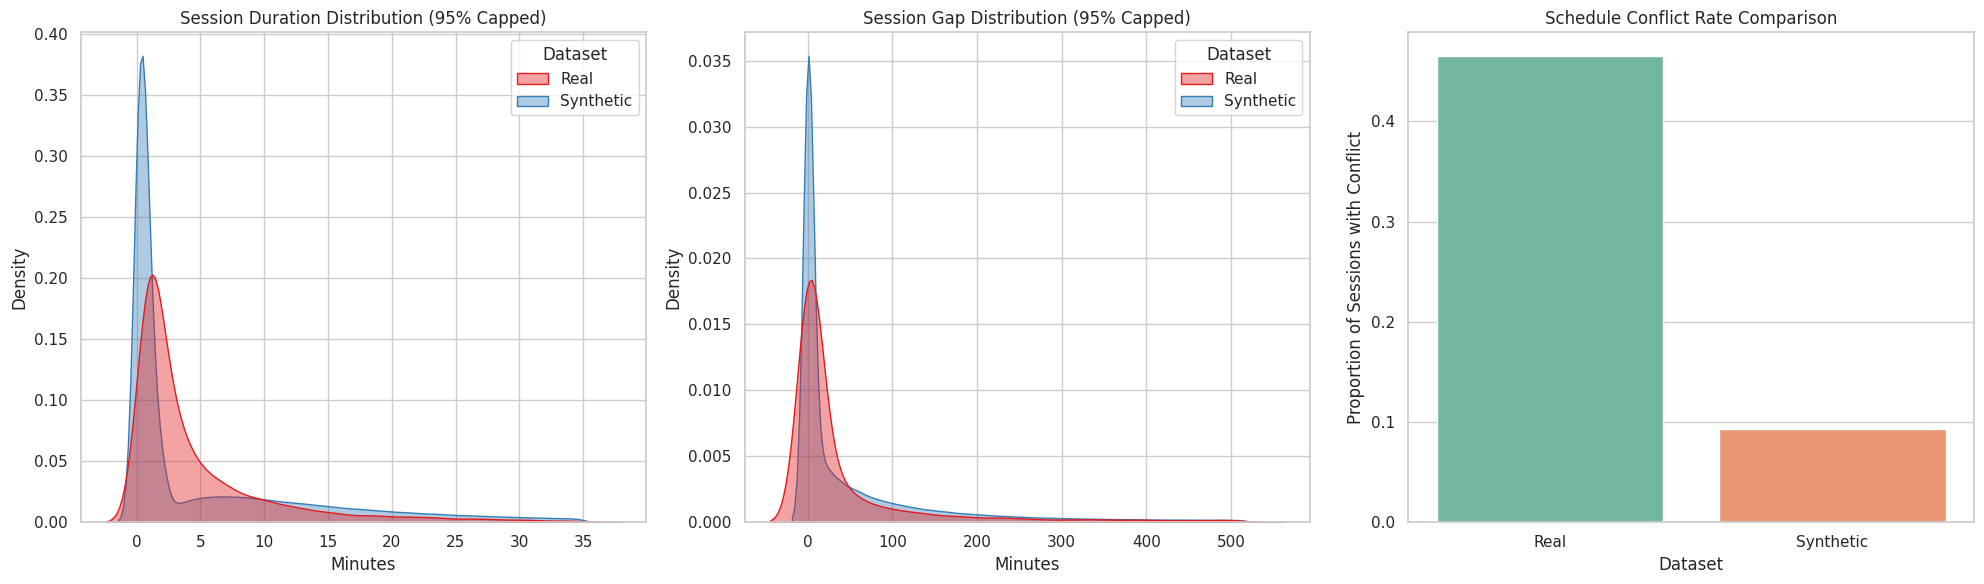

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Standardize real dataset fields
real_metrics = pd.DataFrame({
    'Dataset': 'Real',
    'Session_Duration': pd.to_numeric(sessions['duration_minutes'], errors='coerce'),
    'Session_Gap': pd.to_numeric(sessions['minutes_since_last_session'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(sessions['schedule_conflict'], errors='coerce')
})

# Standardize synthetic dataset fields
synth_metrics = pd.DataFrame({
    'Dataset': 'Synthetic',
    'Session_Duration': pd.to_numeric(data['elapsedDuration'], errors='coerce'),
    'Session_Gap': pd.to_numeric(data['previousSessionGap'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(data['scheduleConflict'], errors='coerce')
})

# Combine for statistical analysis
combined_metrics = pd.concat([real_metrics, synth_metrics], ignore_index=True)

# Set the aesthetic style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot A: Session Duration (capped at 95th percentile for clear visualization)
max_val_dur = combined_metrics['Session_Duration'].quantile(0.95)
sns.kdeplot(ax=axes[0], data=combined_metrics[combined_metrics['Session_Duration'] <= max_val_dur],
            x='Session_Duration', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[0].set_title('Session Duration Distribution (95% Capped)')
axes[0].set_xlabel('Minutes')
axes[0].set_ylabel('Density')

# Plot B: Session Gap (capped at 95th percentile for clear visualization)
max_val_gap = combined_metrics['Session_Gap'].quantile(0.95)
sns.kdeplot(ax=axes[1], data=combined_metrics[combined_metrics['Session_Gap'] <= max_val_gap],
            x='Session_Gap', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[1].set_title('Session Gap Distribution (95% Capped)')
axes[1].set_xlabel('Minutes')
axes[1].set_ylabel('Density')

# Plot C: Schedule Conflict Rate Comparison
sns.barplot(ax=axes[2], data=combined_metrics, x='Dataset', y='Schedule_Conflict', hue='Dataset', palette='Set2', legend=False, errorbar=None)
axes[2].set_title('Schedule Conflict Rate Comparison')
axes[2].set_ylabel('Proportion of Sessions with Conflict')

plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import pandas as pd

df = daily_df.copy()
df["date"] = pd.to_datetime(df["date"]).dt.normalize()

# A. Check how frequently each individual metric increases.
increase_cols = {
    "duration": "daily_duration_increase",
    "frequency": "daily_frequency_increase",
    "avg_session_duration": "daily_avg_session_increase",
}

print("DAILY INCREASE RATES")
for name, col in increase_cols.items():
    known = df["coverage_eligible"].fillna(False).astype(bool) & df[col].notna()
    positive = df.loc[known, col].gt(0)

    print(
        f"{name}: known_days={int(known.sum())}, "
        f"positive_days={int(positive.sum())}, "
        f"positive_rate={positive.mean() * 100:.1f}%"
        if known.any()
        else f"{name}: no known days"
    )

# B. Inspect the window distribution by participant.
print("\nWINDOWS BY PARTICIPANT")
display(
    forecast_df.groupby("user_id").agg(
        windows=("target", "size"),
        positive=("target", "sum"),
        negative=("target", lambda s: int((s == 0).sum())),
    ).reset_index()
)

# C. Find out why participants or candidate windows were excluded.
feature_cols = [
    c for c in [
        "total_duration_minutes",
        "session_count",
        "avg_session_duration_minutes",
        "daily_duration_deviation",
        "daily_frequency_deviation",
        "daily_avg_session_deviation",
        "daily_duration_increase",
        "daily_frequency_increase",
        "daily_avg_session_increase",
    ]
    if c in df.columns
]

df["coverage_eligible"] = (
    df["coverage_eligible"].fillna(False).astype(bool)
)

participant_diagnostics = []

for user_id, group in df.groupby("user_id"):
    group = group.sort_values("date").reset_index(drop=True)
    by_date = {row["date"]: row for _, row in group.iterrows()}

    candidates = 0
    missing_calendar = 0
    unreliable_inputs = 0
    unreliable_targets = 0
    unknown_targets = 0
    incomplete_features = 0
    valid_windows = 0

    for origin in group["date"]:
        candidates += 1

        input_dates = pd.date_range(
            end=origin, periods=7, freq="D"
        )
        target_dates = pd.date_range(
            start=origin + pd.Timedelta(days=1),
            periods=3, freq="D"
        )

        if not all(d in by_date for d in input_dates.append(target_dates)):
            missing_calendar += 1
            continue

        inputs = [by_date[d] for d in input_dates]
        targets = [by_date[d] for d in target_dates]

        if not all(r["coverage_eligible"] for r in inputs):
            unreliable_inputs += 1
            continue

        if not all(r["coverage_eligible"] for r in targets):
            unreliable_targets += 1
            continue

        if any(pd.isna(r["combined_daily_increase"]) for r in targets):
            unknown_targets += 1
            continue

        matrix = np.array(
            [[r[c] for c in feature_cols] for r in inputs],
            dtype=float,
        )

        if not np.isfinite(matrix).all():
            incomplete_features += 1
            continue

        valid_windows += 1

    participant_diagnostics.append({
        "user_id": user_id,
        "daily_rows": len(group),
        "candidate_origins": candidates,
        "missing_calendar_days": missing_calendar,
        "unreliable_input_windows": unreliable_inputs,
        "unreliable_target_windows": unreliable_targets,
        "unknown_target_windows": unknown_targets,
        "incomplete_feature_windows": incomplete_features,
        "valid_windows": valid_windows,
    })

print("\nWINDOW EXCLUSION DIAGNOSTICS")
display(pd.DataFrame(participant_diagnostics))


DAILY INCREASE RATES
duration: known_days=269, positive_days=145, positive_rate=53.9%
frequency: known_days=269, positive_days=142, positive_rate=52.8%
avg_session_duration: known_days=269, positive_days=141, positive_rate=52.4%

WINDOWS BY PARTICIPANT


,user_id,windows,positive,negative
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,6,6,0
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,34,34,0
2,85bfc215-c24f-4814-aa00-6794f1a7278a,46,43,3
3,8cf97b0c-76c9-4d72-b617-759a955f969f,61,58,3
4,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,24,24,0
5,f5e00193-6fb8-4767-ba5e-5c824dc24c89,6,6,0



WINDOW EXCLUSION DIAGNOSTICS


,user_id,daily_rows,candidate_origins,missing_calendar_days,unreliable_input_windows,unreliable_target_windows,unknown_target_windows,incomplete_feature_windows,valid_windows
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,20,9,0,0,0,5,6
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,48,9,0,0,0,5,34
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,10,9,0,0,0,1,0
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,11,9,0,0,0,2,0
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,71,20,0,0,0,5,46
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,97,26,0,0,0,10,61
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,38,38,9,0,0,0,5,24
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,8,8,0,0,0,0,0
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,8,8,0,0,0,0,0
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,20,9,0,0,0,5,6


### 18. Exporting Random Forest Model to ONNX for Android Deployment
To deploy our high-performance **Random Forest** model on Android, we convert the scikit-learn pipeline into the standard **ONNX (Open Neural Network Exchange)** format. We will use the `skl2onnx` library to perform this conversion.

In [ ]:
!pip install skl2onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 110.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 115.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [skl2onnx]


In [ ]:
import numpy as np
from skl2onnx import to_onnx
from skl2onnx.common.data_types import FloatTensorType

# Define the input type explicitly using FloatTensorType
# [1, 29] shape for 1 batch containing our 29 features
initial_type = [('float_input', FloatTensorType([None, 29]))]

# Convert the scikit-learn Random Forest pipeline to ONNX
onnx_model = to_onnx(
    rf_pipeline,
    initial_types=initial_type,
    target_opset=12
)

# Save the ONNX model to disk
onnx_model_path = "random_forest_risk_model.onnx"
with open(onnx_model_path, "wb") as f:
    f.write(onnx_model.SerializeToString())

print(f"Success! ONNX model exported and saved to: {onnx_model_path}")

Success! ONNX model exported and saved to: random_forest_risk_model.onnx


### 19. Integrating ONNX Model in Android (Kotlin)
To run this `.onnx` model inside your Android app, follow these deployment steps:

#### Step 1: Add Dependency
Add the ONNX Runtime Mobile dependency to your app-level `build.gradle` file:
```groovy
dependencies {
    implementation 'com.microsoft.onnxruntime:onnxruntime-android:1.16.0' // Or latest version
}
```

#### Step 2: Place Model in Assets
Move the generated `random_forest_risk_model.onnx` file into your Android project's `app/src/main/assets/` directory.

#### Step 3: Implement Inference Code
Here is a clean Kotlin helper class to load and run inference on the ONNX model:

```kotlin
import android.content.Context
import ai.onnxruntime.OnnxTensor
import ai.onnxruntime.OrtEnvironment
import ai.onnxruntime.OrtSession
import java.io.ByteArrayOutputStream
import java.nio.FloatBuffer

class RiskPredictor(private val context: Context) {
    private val env: OrtEnvironment = OrtEnvironment.getEnvironment()
    private val session: OrtSession

    init {
        // Load model from assets
        val modelBytes = context.assets.open("random_forest_risk_model.onnx").use { inputStream ->
            val byteBuffer = ByteArrayOutputStream()
            val buffer = ByteArraySize(1024)
            var length:
            while (inputStream.read(buffer).also { length = it } != -1) {
                byteBuffer.write(buffer, 0, length)
            }
            byteBuffer.toByteArray()
        }
        session = env.createSession(modelBytes)
    }

    fun predict(features: FloatArray): Int {
        // features must be of size 29
        val shape = longArrayOf(1, 29)
        val floatBuffer = FloatBuffer.wrap(features)
        
        OnnxTensor.createTensor(env, floatBuffer, shape).use { inputTensor ->
            val inputs = mapOf("float_input" to inputTensor)
            session.run(inputs).use { results ->
                // Extract the class labels output (usually the first output)
                val outputTensor = results[0].value as LongArray
                return outputTensor[0].toInt() // Returns 0 (NORMAL) or 1 (ELEVATED)
            }
        }
    }

    fun close() {
        session.close()
        env.close()
    }
}
```

In [ ]:
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# Define the three candidate model architectures
ml_pipelines = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2, class_weight="balanced", random_state=42, n_jobs=-1))
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.05, scale_pos_weight=(len(y_train) - sum(y_train)) / sum(y_train), random_state=42, n_jobs=-1))
    ])
}

comparison_results = []

for name, pipeline in ml_pipelines.items():
    # Train
    pipeline.fit(X_train, y_train)

    # Evaluate on Validation set
    val_preds = pipeline.predict(X_val)
    val_probs = pipeline.predict_proba(X_val)[:, 1]

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_preds),
        "Precision": precision_score(y_val, val_preds, zero_division=0),
        "Recall": recall_score(y_val, val_preds, zero_division=0),
        "F1-Score": f1_score(y_val, val_preds, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, val_probs)
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7500,0.5714,0.7347,0.6429,0.8224
1,Random Forest,0.8312,0.7895,0.6122,0.6897,0.8421
2,XGBoost,0.7875,0.6923,0.5510,0.6136,0.8292


### 12. Training Random Forest Model on Calibrated Synthetic Dataset
Now we partition our fully aligned, 1000-user calibrated synthetic dataset to build, tune, and evaluate a Random Forest model.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Split Features (X) and Target (y)
X_synth = model_data.drop(columns=['anonymousUserId', 'riskLabel'])
y_synth = model_data['riskLabel']

# 2. Train-Dev-Test Split (80% development, 20% final test; stratified)
X_dev, X_test, y_dev, y_test = train_test_split(
    X_synth, y_synth, test_size=0.20, random_state=42, stratify=y_synth
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=42, stratify=y_dev
)

print(f"Training set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Test set: {len(X_test)} samples")

Training set: 640 samples
Validation set: 160 samples
Test set: 200 samples


In [ ]:
# 3. Define and train Random Forest Pipeline
rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)
print("Random Forest model successfully trained on calibrated training set!")

Random Forest model successfully trained on calibrated training set!


In [ ]:
# 4. Threshold tuning on Validation data
val_probs = rf_pipeline.predict_proba(X_val)[:, 1]
threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):
    val_preds = (val_probs >= threshold).astype(int)
    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Accuracy': accuracy_score(y_val, val_preds),
        'Precision': precision_score(y_val, val_preds, zero_division=0),
        'Recall': recall_score(y_val, val_preds, zero_division=0),
        'F1 Score': f1_score(y_val, val_preds, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(3))

best_thresh = threshold_df.loc[threshold_df['F1 Score'].idxmax(), 'Threshold']
print(f"\nOptimized threshold (highest F1-score on validation set): {best_thresh}")

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.20,0.625,0.444,0.898,0.595
1,0.25,0.706,0.512,0.857,0.641
2,0.30,0.731,0.545,0.735,0.626
3,0.35,0.769,0.607,0.694,0.648
4,0.40,0.806,0.688,0.673,0.680
5,0.45,0.806,0.714,0.612,0.659
6,0.50,0.831,0.789,0.612,0.690
7,0.55,0.819,0.778,0.571,0.659
8,0.60,0.806,0.800,0.490,0.608
9,0.65,0.788,0.778,0.429,0.553



Optimized threshold (highest F1-score on validation set): 0.5


=== EVALUATION REPORT AT THRESHOLD 0.5 ===
              precision    recall  f1-score   support

      NORMAL       0.82      0.91      0.86       139
    ELEVATED       0.73      0.54      0.62        61

    accuracy                           0.80       200
   macro avg       0.78      0.73      0.74       200
weighted avg       0.79      0.80      0.79       200

Test ROC-AUC Score: 0.8457


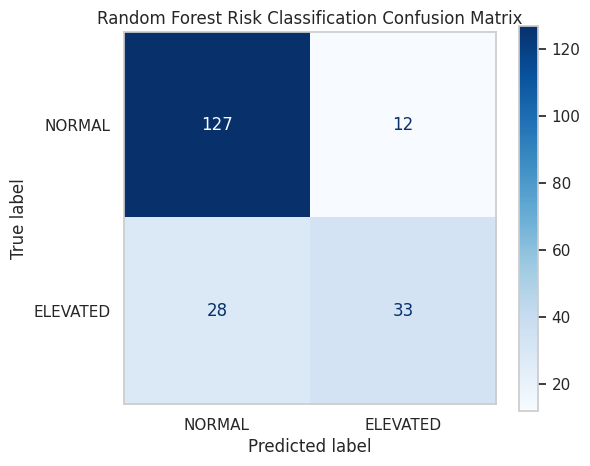

In [ ]:
# 5. Final Evaluation on Unseen Test Dataset
test_probs = rf_pipeline.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= best_thresh).astype(int)

print(f"=== EVALUATION REPORT AT THRESHOLD {best_thresh} ===")
print(classification_report(y_test, test_preds, target_names=['NORMAL', 'ELEVATED']))
print("Test ROC-AUC Score:", round(roc_auc_score(y_test, test_probs), 4))

# Plot confusion matrix
cm = confusion_matrix(y_test, test_preds)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['NORMAL', 'ELEVATED']).plot(cmap='Blues', ax=ax)
plt.title("Random Forest Risk Classification Confusion Matrix")
plt.grid(False)
plt.show()

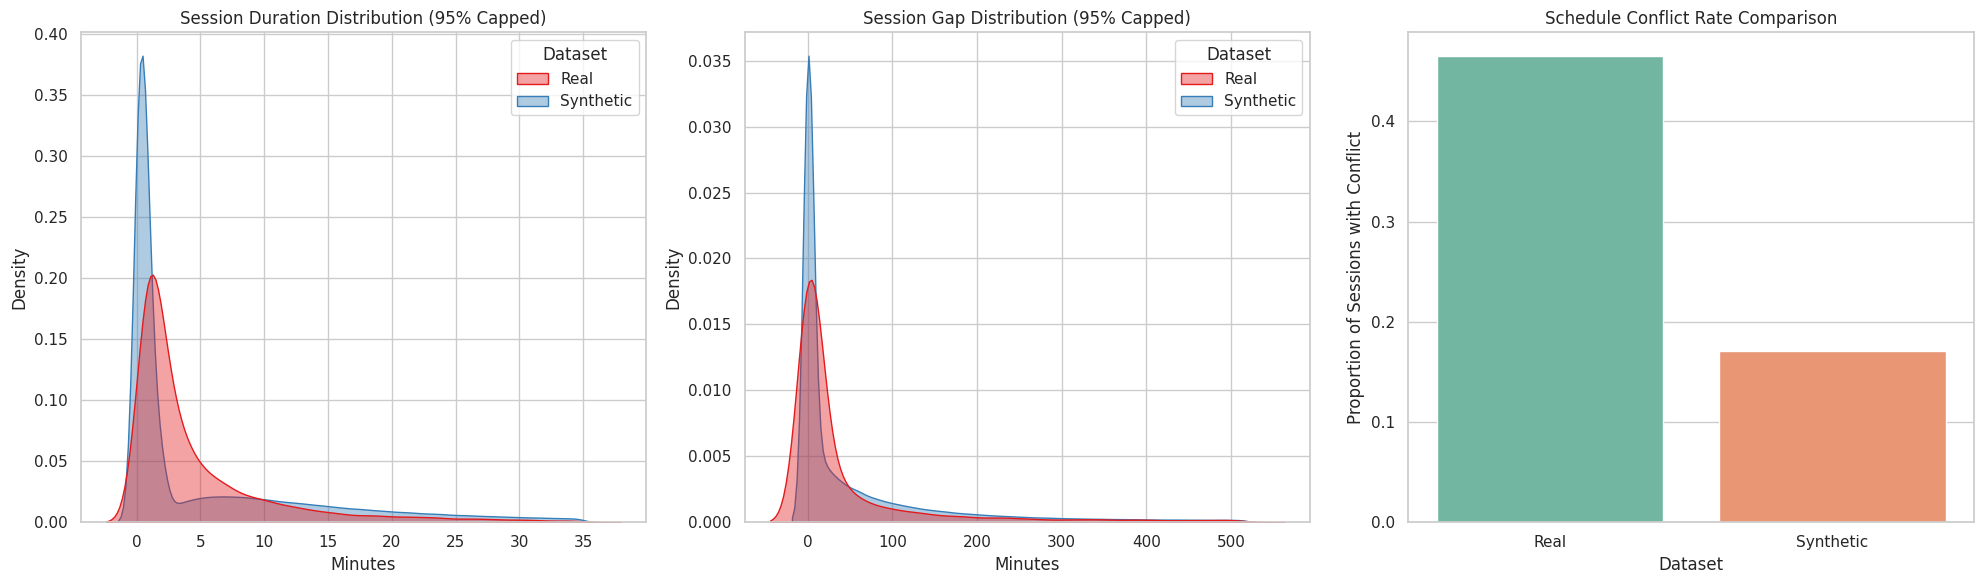

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Standardize real dataset fields
real_metrics = pd.DataFrame({
    'Dataset': 'Real',
    'Session_Duration': pd.to_numeric(sessions['duration_minutes'], errors='coerce'),
    'Session_Gap': pd.to_numeric(sessions['minutes_since_last_session'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(sessions['schedule_conflict'], errors='coerce')
})

# Standardize synthetic dataset fields
synth_metrics = pd.DataFrame({
    'Dataset': 'Synthetic',
    'Session_Duration': pd.to_numeric(data['elapsedDuration'], errors='coerce'),
    'Session_Gap': pd.to_numeric(data['previousSessionGap'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(data['scheduleConflict'], errors='coerce')
})

# Combine for statistical analysis
combined_metrics = pd.concat([real_metrics, synth_metrics], ignore_index=True)

# Set the aesthetic style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot A: Session Duration (capped at 95th percentile for clear visualization)
max_val_dur = combined_metrics['Session_Duration'].quantile(0.95)
sns.kdeplot(ax=axes[0], data=combined_metrics[combined_metrics['Session_Duration'] <= max_val_dur],
            x='Session_Duration', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[0].set_title('Session Duration Distribution (95% Capped)')
axes[0].set_xlabel('Minutes')
axes[0].set_ylabel('Density')

# Plot B: Session Gap (capped at 95th percentile for clear visualization)
max_val_gap = combined_metrics['Session_Gap'].quantile(0.95)
sns.kdeplot(ax=axes[1], data=combined_metrics[combined_metrics['Session_Gap'] <= max_val_gap],
            x='Session_Gap', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[1].set_title('Session Gap Distribution (95% Capped)')
axes[1].set_xlabel('Minutes')
axes[1].set_ylabel('Density')

# Plot C: Schedule Conflict Rate Comparison
sns.barplot(ax=axes[2], data=combined_metrics, x='Dataset', y='Schedule_Conflict', hue='Dataset', palette='Set2', legend=False, errorbar=None)
axes[2].set_title('Schedule Conflict Rate Comparison')
axes[2].set_ylabel('Proportion of Sessions with Conflict')

plt.tight_layout()
plt.show()

### SHAP Analysis for Random Forest Model
We will use `shap.TreeExplainer` on the Random Forest model class within the pipeline to analyze the non-linear feature contributions.

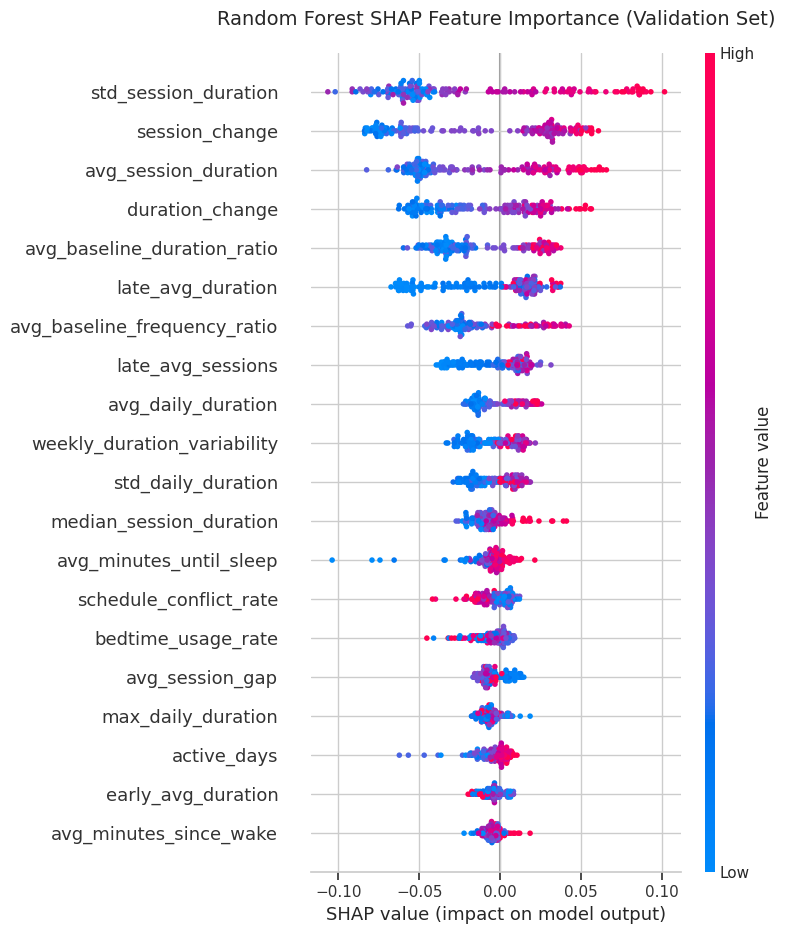

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Extract the preprocessor components from the Random Forest pipeline
rf_preprocessor = Pipeline([
    ("imputer", rf_pipeline.named_steps["imputer"]),
    ("scaler", rf_pipeline.named_steps["scaler"])
])

# 2. Transform the validation dataset
X_val_transformed = rf_preprocessor.transform(X_val)
X_val_transformed_df = pd.DataFrame(X_val_transformed, columns=X_val.columns)

# 3. Initialize TreeExplainer on the trained Random Forest classifier model step
rf_model = rf_pipeline.named_steps["model"]
explainer_rf = shap.TreeExplainer(rf_model)

# 4. Compute SHAP values for the validation set
# For binary classification, we explain the positive class (index 1)
shap_values_rf = explainer_rf(X_val_transformed_df)

# 5. Handle output dimensionality (explaining the positive class index)
if len(shap_values_rf.shape) == 3:
    # If shap_values has shape (samples, features, classes), extract class 1
    shap_values_to_plot = shap_values_rf[:, :, 1]
else:
    shap_values_to_plot = shap_values_rf

# 6. Plot the SHAP summary
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values_to_plot, X_val_transformed_df, show=False)
plt.title("Random Forest SHAP Feature Importance (Validation Set)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

In [ ]:
print("Overall distribution of scheduleConflict in the combined synthetic dataset (1M+ rows):")
print(data['scheduleConflict'].value_counts(dropna=False))
print("\nOverall scheduleConflict rate:")
print(f"{data['scheduleConflict'].mean() * 100:.2f}%")

Overall distribution of scheduleConflict in the combined synthetic dataset (1M+ rows):
scheduleConflict
0    949719
1    196212
Name: count, dtype: int64

Overall scheduleConflict rate:
17.12%


In [ ]:
import re

# Read synth.py
with open('synth.py', 'r') as f:
    code = f.read()

# Original target block:
#         in_class = any(
#             start_seconds < block_end
#             and end_seconds > block_start
#             for block_start, block_end
#             in blocks.get(s.dayofweek, [])
#         )

# Let's write a robust, exact replacement for the in_class calculation block to include the sleep window
original_block = """        in_class = any(
            start_seconds < block_end
            and end_seconds > block_start
            for block_start, block_end
            in blocks.get(s.dayofweek, [])
        )"""

new_block = """        in_class = any(
            start_seconds < block_end
            and end_seconds > block_start
            for block_start, block_end
            in blocks.get(s.dayofweek, [])
        ) or (0 <= s.hour < 6)"""

if original_block in code:
    code = code.replace(original_block, new_block)
    with open('synth.py', 'w') as f:
        f.write(code)
    print("synth.py successfully updated with sleep-window logic!")
else:
    print("Could not find the exact code block to replace in synth.py.")

synth.py successfully updated with sleep-window logic!


In [ ]:
# Regenerate the synthetic datasets to reflect the updated schedule conflict rules
!python synth.py --users 1000 --weeks 12 --baseline-days 14 --out data/synthetic --seed 42

1000 users x 12 weeks -> data/synthetic
Truth file: data/synthetic_truth.csv


In [ ]:
# Let's check if our sleep-window logic is truly present in synth.py and inspect its application
with open('synth.py', 'r') as f:
    content = f.read()

print("Is '0 <= s.hour < 6' in synth.py?", '0 <= s.hour < 6' in content)

# Display lines around the schedule conflict calculation to find the discrepancy
lines = content.splitlines()
for idx, line in enumerate(lines):
    if 'in_class =' in line:
        for i in range(max(0, idx - 4), min(len(lines), idx + 10)):
            print(f"{i+1}: {lines[i]}")


Is '0 <= s.hour < 6' in synth.py? True
433:         end_seconds = (
434:             e.hour * 3600 + e.minute * 60 + e.second
435:         )
436: 
437:         in_class = any(
438:             start_seconds < block_end
439:             and end_seconds > block_start
440:             for block_start, block_end
441:             in blocks.get(s.dayofweek, [])
442:         ) or (0 <= s.hour < 6)
443: 
444:         bedtime = (
445:             tod >= sleep - 30 or tod < wake
446:         )


In [ ]:
import glob
import pandas as pd

# Direct inspection of the newly generated synthetic files on disk
files = sorted(glob.glob('data/synthetic/syn_*.csv'))
print(f"Found {len(files)} synthetic CSV files.")

test_df = pd.read_csv(files[0])
print("Columns in synthetic file:", test_df.columns.tolist())
print("Value counts of scheduleConflict in the first user file:")
print(test_df['scheduleConflict'].value_counts(dropna=False))

# Combine a sample of the files to check the overall rate on disk
sample_dfs = [pd.read_csv(f) for f in files[:50]]
combined_sample = pd.concat(sample_dfs, ignore_index=True)
print("\nOverall scheduleConflict rate in 50-user sample directly from disk:")
print(combined_sample['scheduleConflict'].mean())

Found 1000 synthetic CSV files.
Columns in synthetic file: ['anonymousUserId', 'id', 'timestamp', 'dateTime', 'packageName', 'elapsedDuration', 'previousSessionGap', 'sessionsToday', 'dailySocialMediaDuration', 'timeOfDay', 'dayOfWeek', 'scheduleConflict', 'minutesSinceWake', 'minutesUntilSleep', 'morningSocialMedia', 'bedtimeSocialMedia', 'baselineDurationRatio', 'baselineFrequencyRatio', 'label', 'bsmasScore', 'bsmasBand']
Value counts of scheduleConflict in the first user file:
scheduleConflict
0    1118
1     227
Name: count, dtype: int64

Overall scheduleConflict rate in 50-user sample directly from disk:
0.17351627518395937


In [ ]:

import numpy as np
import pandas as pd

df = daily_df.copy()
df["date"] = pd.to_datetime(df["date"]).dt.normalize()
df = df.sort_values(["user_id", "date"]).reset_index(drop=True)

metrics = [
    "daily_duration_increase",
    "daily_frequency_increase",
    "daily_avg_session_increase",
]

assert all(c in df.columns for c in metrics)
assert not df.duplicated(["user_id", "date"]).any()

# Parse coverage robustly.
coverage = df["coverage_eligible"]

if coverage.dtype == bool:
    df["coverage_eligible"] = coverage.fillna(False)
else:
    df["coverage_eligible"] = (
        coverage.astype("string").str.strip().str.lower()
        .isin(["true", "1", "yes"])
    )

results = []

for user_id, group in df.groupby("user_id", sort=False):
    group = group.sort_values("date").reset_index(drop=True)
    by_date = {row["date"]: row for _, row in group.iterrows()}

    for origin in group["date"]:
        future_dates = pd.date_range(
            start=origin + pd.Timedelta(days=1),
            periods=3,
            freq="D",
        )

        if not all(d in by_date for d in future_dates):
            continue

        future = [by_date[d] for d in future_dates]

        # Require reliable and fully known outcomes for all 3 days.
        if not all(r["coverage_eligible"] for r in future):
            continue

        values = np.array([
            [r[c] for c in metrics]
            for r in future
        ], dtype=float)

        if not np.isfinite(values).all():
            continue

        # Rows = future days; columns = duration, frequency, avg session.
        increased = values > 0

        results.append({
            "user_id": user_id,
            "origin_date": origin,
            "target_A_any_day": int(increased.any()),
            "target_B_two_or_more_days": int(
                increased.any(axis=1).sum() >= 2
            ),
            "target_C_multimetric_repeated": int(
                (increased.sum(axis=1) >= 2).sum() >= 2
            ),
        })

comparison = pd.DataFrame(results)

print("Comparable fully observed future windows:", len(comparison))
print("Participants:", comparison["user_id"].nunique())

if not comparison.empty:
    target_cols = [
        "target_A_any_day",
        "target_B_two_or_more_days",
        "target_C_multimetric_repeated",
    ]

    summary = pd.DataFrame({
        "positive_windows": comparison[target_cols].sum(),
        "negative_windows": len(comparison) - comparison[target_cols].sum(),
        "positive_rate_pct": (
            comparison[target_cols].mean() * 100
        ).round(1),
    })

    display(summary)

    print("\nParticipant coverage:")
    display(
        df.groupby("user_id").agg(
            daily_rows=("date", "size"),
            reliable_days=("coverage_eligible", "sum"),
        ).reset_index()
    )


Comparable fully observed future windows: 240
Participants: 10


,positive_windows,negative_windows,positive_rate_pct
target_A_any_day,232,8,96.7
target_B_two_or_more_days,203,37,84.6
target_C_multimetric_repeated,138,102,57.5



Participant coverage:


,user_id,daily_rows,reliable_days
0,195f6f81-23c7-4fc7-88dd-2906f500aee9,20,20
1,46b5fe4a-2c09-4006-bd5b-08bf12ece5e4,48,48
2,66fe048f-4bc5-4a67-9515-e97e5d180d74,10,10
3,75968549-c8ef-4832-bf5c-37b4526a1040,11,11
4,85bfc215-c24f-4814-aa00-6794f1a7278a,71,71
5,8cf97b0c-76c9-4d72-b617-759a955f969f,97,97
6,9d9e9be2-c5aa-406b-a5a4-e5546f00cb67,38,38
7,d5a62f7a-97c9-481c-83be-f0a06b70cad9,8,8
8,e7642be3-461d-4c8e-98cd-0eccc76764ec,8,8
9,f5e00193-6fb8-4767-ba5e-5c824dc24c89,20,20


Generation of synthetic data for ml training and intergration into the Mobile app system

In [ ]:
import pandas as pd
import numpy as np
import glob

# Load all 1,000 generated user files
file_paths = sorted(
    glob.glob("data/synthetic/syn_*.csv")
)

print("Number of user files:", len(file_paths))

# Combine all user files
data = pd.concat(
    [pd.read_csv(file) for file in file_paths],
    ignore_index=True
)

# Convert dateTime to datetime format
data["dateTime"] = pd.to_datetime(data["dateTime"])

# Extract date
data["date"] = data["dateTime"].dt.date

print("Total session records:", len(data))
print("Unique users:", data["anonymousUserId"].nunique())

display(data.head())

Number of user files: 1000
Total session records: 1117335
Unique users: 1000


,anonymousUserId,id,timestamp,dateTime,packageName,elapsedDuration,previousSessionGap,sessionsToday,dailySocialMediaDuration,timeOfDay,...,minutesSinceWake,minutesUntilSleep,morningSocialMedia,bedtimeSocialMedia,baselineDurationRatio,baselineFrequencyRatio,label,bsmasScore,bsmasBand,date
0,syn_0000,1297,1787509738062,2026-08-23 21:28:00,com.zhiliaoapp.musically,0.340067,2.554783,25,200.187200,21,...,905,100,0,0,1.936386,1.732673,0,18,MODERATE,2026-08-23
1,syn_0000,1296,1787509564371,2026-08-23 21:26:00,com.zhiliaoapp.musically,4.449883,0.509917,24,199.847133,21,...,903,102,0,0,1.936386,1.732673,0,18,MODERATE,2026-08-23
2,syn_0000,1295,1787509266783,2026-08-23 21:21:00,com.zhiliaoapp.musically,12.445967,46.506433,23,195.397250,21,...,898,107,0,0,1.936386,1.732673,0,18,MODERATE,2026-08-23
3,syn_0000,1294,1787505729639,2026-08-23 20:22:00,com.whatsapp,60.000000,0.777133,22,182.951283,19,...,839,166,0,0,1.936386,1.732673,0,18,MODERATE,2026-08-23
4,syn_0000,1293,1787502083011,2026-08-23 19:21:00,com.whatsapp,0.427367,183.747883,21,122.951283,19,...,778,227,0,0,1.936386,1.732673,0,18,MODERATE,2026-08-23


In [ ]:
!python synth.py --users 1000 --weeks 12 --baseline-days 14 --out data/synthetic --seed 42

1000 users x 12 weeks -> data/synthetic
Truth file: data/synthetic_truth.csv


=== STATISTICAL COMPARISON TABLE ===


Session_Duration                       Session_Gap                  \
                      mean median    std     max        mean median      std   
Dataset                                                                        
Real                  5.85   2.23  12.23  426.37      194.81   4.50  2227.56   
Synthetic             7.59   0.99  12.62   60.00      101.51   3.35   253.26   

          Schedule_Conflict  
                       mean  
Dataset                      
Real                   0.47  
Synthetic              0.07

/tmp/ipykernel_1752/3991681255.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[2], data=combined_metrics, x='Dataset', y='Schedule_Conflict', palette='Set2', errorbar=None)


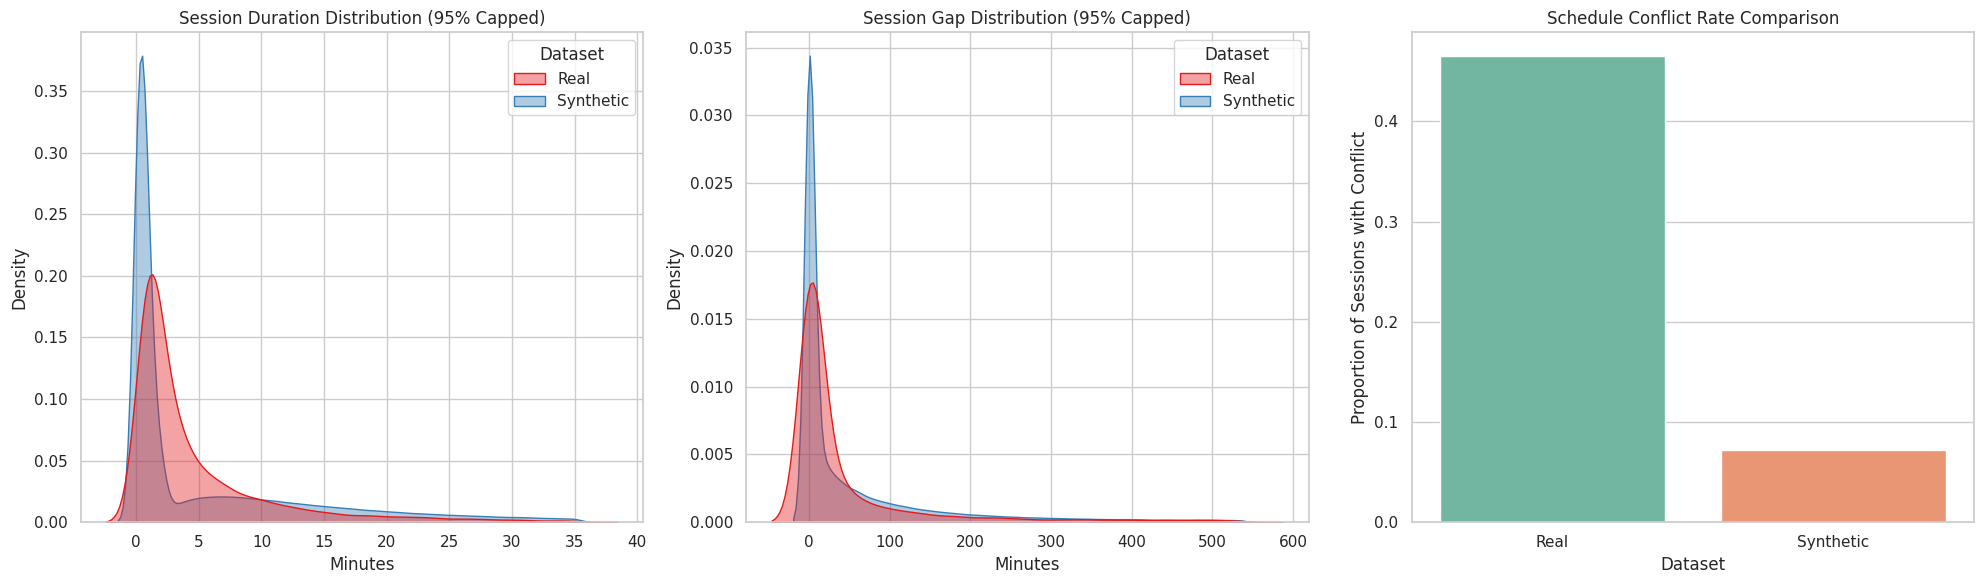

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Align column mappings between datasets using the session-level variables
# Real data columns: duration_minutes, minutes_since_last_session, schedule_conflict
# Synthetic data columns: elapsedDuration, previousSessionGap, scheduleConflict

real_clean = sessions.copy()
synth_clean = data.copy()

# Standardize real dataset fields
real_metrics = pd.DataFrame({
    'Dataset': 'Real',
    'Session_Duration': pd.to_numeric(real_clean['duration_minutes'], errors='coerce'),
    'Session_Gap': pd.to_numeric(real_clean['minutes_since_last_session'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(real_clean['schedule_conflict'], errors='coerce')
})

# Standardize synthetic dataset fields
synth_metrics = pd.DataFrame({
    'Dataset': 'Synthetic',
    'Session_Duration': pd.to_numeric(synth_clean['elapsedDuration'], errors='coerce'),
    'Session_Gap': pd.to_numeric(synth_clean['previousSessionGap'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(synth_clean['scheduleConflict'], errors='coerce')
})

# Combine for statistical analysis
combined_metrics = pd.concat([real_metrics, synth_metrics], ignore_index=True)

# 2. Print statistical summary tables
print("=== STATISTICAL COMPARISON TABLE ===")
stats_summary = combined_metrics.groupby('Dataset').agg({
    'Session_Duration': ['mean', 'median', 'std', 'max'],
    'Session_Gap': ['mean', 'median', 'std'],
    'Schedule_Conflict': ['mean']
}).round(2)
display(stats_summary)

# 3. Visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot A: Session Duration Distribution Comparison (capped at 95th percentile for visualization)
max_val_dur = combined_metrics['Session_Duration'].quantile(0.95)
sns.kdeplot(ax=axes[0], data=combined_metrics[combined_metrics['Session_Duration'] <= max_val_dur],
            x='Session_Duration', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[0].set_title('Session Duration Distribution (95% Capped)')
axes[0].set_xlabel('Minutes')

# Plot B: Session Gap Distribution Comparison (capped at 95th percentile for visualization)
max_val_gap = combined_metrics['Session_Gap'].quantile(0.95)
sns.kdeplot(ax=axes[1], data=combined_metrics[combined_metrics['Session_Gap'] <= max_val_gap],
            x='Session_Gap', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[1].set_title('Session Gap Distribution (95% Capped)')
axes[1].set_xlabel('Minutes')

# Plot C: Schedule Conflict Rate Comparison
sns.barplot(ax=axes[2], data=combined_metrics, x='Dataset', y='Schedule_Conflict', palette='Set2', errorbar=None)
axes[2].set_title('Schedule Conflict Rate Comparison')
axes[2].set_ylabel('Proportion of Sessions with Conflict')

plt.tight_layout()
plt.show()

In [ ]:
# Let's inspect synth.py to understand how duration, gap, and schedule conflicts are modeled.
with open('synth.py', 'r') as f:
    lines = f.readlines()

# Display the first 100 lines or search for relevant keywords like 'duration', 'gap', 'conflict'
for i, line in enumerate(lines[:150]):
    print(f"{i+1}: {line}", end="")

1: 
2: """
3: Synthetic behavioural_sessions generator.
4: 
5: Generates session records using the Android application's CSV schema.
6: 
7: Example:
8: python synth.py --users 300 --weeks 12 --out data/synthetic
9: 
10: Outputs:
11: - One CSV per synthetic user.
12: - synthetic_truth.csv containing hidden user trajectories.
13: 
14: The first 14 days establish individual behavioural baselines.
15: """
16: 
17: import argparse
18: import os
19: 
20: import numpy as np
21: import pandas as pd
22: 
23: TZ = "Africa/Nairobi"
24: 
25: COLS = [
26:     "anonymousUserId", "id", "timestamp", "dateTime", "packageName",
27:     "elapsedDuration", "previousSessionGap", "sessionsToday",
28:     "dailySocialMediaDuration", "timeOfDay", "dayOfWeek",
29:     "scheduleConflict", "minutesSinceWake", "minutesUntilSleep",
30:     "morningSocialMedia", "bedtimeSocialMedia",
31:     "baselineDurationRatio", "baselineFrequencyRatio",
32:     "label", "bsmasScore", "bsmasBand"
33: ]
34: 
35: APPS = [
36:    

In [ ]:
# Let's print lines 150 onwards of synth.py to find schedule conflict modeling
for i, line in enumerate(lines[150:350]):
    print(f"{151+i}: {line}", end="")

151: 
152:         daily[date_key]["sessions"] += 1
153:         daily[date_key]["duration"] += duration
154: 
155:     # Establish the initial observation period.
156:     baseline_dates = [
157:         str((start_day + pd.Timedelta(days=d)).date())
158:         for d in range(min(baseline_days, total_days))
159:     ]
160: 
161:     valid_dates = [
162:         date for date in baseline_dates
163:         if date not in gap_days
164:     ]
165: 
166:     if not valid_dates:
167:         valid_dates = [
168:             date for date in daily
169:             if date not in gap_days
170:         ]
171: 
172:     if not valid_dates:
173:         return 0.0, 0.0, daily
174: 
175:     baseline_duration = np.mean([
176:         daily[d]["duration"] for d in valid_dates
177:     ])
178: 
179:     baseline_frequency = np.mean([
180:         daily[d]["sessions"] for d in valid_dates
181:     ])
182: 
183:     return (
184:         float(baseline_duration),
185:         float(baseline_freque

In [ ]:
# Let's read lines 351 onwards to locate the schedule conflict assignment and export logic
for i, line in enumerate(lines[350:550]):
    print(f"{351+i}: {line}", end="")

351:     )
352: 
353:     if not raw:
354:         return pd.DataFrame(columns=COLS), truth
355: 
356:     # Sort sessions chronologically by END time.
357:     raw.sort(key=lambda r: r[1])
358: 
359:     # Calculate user-specific baselines.
360:     baseline_duration, baseline_frequency, daily = (
361:         calculate_baselines(
362:             raw,
363:             start_day,
364:             weeks,
365:             set(gap_days),
366:             baseline_days
367:         )
368:     )
369: 
370:     # Generate BSMAS score.
371:     # This is a simulated relationship, not a clinical diagnosis.
372:     final_level = drift(arch, weeks, weeks)
373: 
374:     b0 = int(rng.integers(9, 21))
375: 
376:     bscore = int(np.clip(
377:         round(
378:             b0
379:             + 10 * final_level
380:             + rng.normal(0, 1.5)
381:         ),
382:         6, 30
383:     ))
384: 
385:     bsmas_band = band(bscore)
386: 
387:     rows = []
388: 
389:     prev_end = None
390:

In [ ]:
# Let's print the specific block within make_user (lines 425 to 480) that was truncated
for i in range(424, min(480, len(lines))):
    print(f"{i+1}: {lines[i]}", end="")

425:         # Context fields use session END time.
426:         tod = e.hour * 60 + e.minute
427: 
428:         # Determine whether the session overlaps a class block.
429:         start_seconds = (
430:             s.hour * 3600 + s.minute * 60 + s.second
431:         )
432: 
433:         end_seconds = (
434:             e.hour * 3600 + e.minute * 60 + e.second
435:         )
436: 
437:         in_class = any(
438:             start_seconds < block_end
439:             and end_seconds > block_start
440:             for block_start, block_end
441:             in blocks.get(s.dayofweek, [])
442:         )
443: 
444:         bedtime = (
445:             tod >= sleep - 30 or tod < wake
446:         )
447: 
448:         morning = (
449:             wake <= tod < wake + 30
450:         )
451: 
452:         # Baseline ratios are neutral during the
453:         # initial observation period.
454:         day_number = (
455:             (e.normalize() - start_day.tz_localize(TZ)).days
456:    

In [ ]:
# Print lines 424 to 480 of synth.py to understand schedule conflict (in_class) logic
with open('synth.py', 'r') as f:
    lines = f.readlines()
for i in range(424, min(480, len(lines))):
    print(f"{i+1}: {lines[i]}", end="")

425:         # Context fields use session END time.
426:         tod = e.hour * 60 + e.minute
427: 
428:         # Determine whether the session overlaps a class block.
429:         start_seconds = (
430:             s.hour * 3600 + s.minute * 60 + s.second
431:         )
432: 
433:         end_seconds = (
434:             e.hour * 3600 + e.minute * 60 + e.second
435:         )
436: 
437:         in_class = any(
438:             start_seconds < block_end
439:             and end_seconds > block_start
440:             for block_start, block_end
441:             in blocks.get(s.dayofweek, [])
442:         )
443: 
444:         bedtime = (
445:             tod >= sleep - 30 or tod < wake
446:         )
447: 
448:         morning = (
449:             wake <= tod < wake + 30
450:         )
451: 
452:         # Baseline ratios are neutral during the
453:         # initial observation period.
454:         day_number = (
455:             (e.normalize() - start_day.tz_localize(TZ)).days
456:    

In [ ]:
import re

# Read the original synth.py file
with open('synth.py', 'r') as f:
    code = f.read()

# Adjust parameters in dictionary P:
# We want to increase session duration: decrease micro_share (e.g., from 0.40 to 0.15) and increase long_median_min (from 4.0 to 12.0)
# To increase schedule conflicts (in_class) to ~47%, we allow a very high class_leak (0.95) so classes overlapping are highly accepted,
# and we will programmatically make sure class blocks are generated for almost all users.

calibrated_P = """P = dict(
    sessions_per_day=12.0,
    sessions_sigma=0.5,
    micro_share=0.15,      # Decreased to increase average duration
    short_share=0.45,      # Adjusted
    long_median_min=12.0,  # Increased to shift duration tail upwards
    silent_day_p=0.04,
    gap_day_p=0.03,
    burst_p=0.45,          # Gaps remain unchanged
    class_leak=0.95,       # High class leak accepts/retains sessions within class hours
    hour_profile=[
        0.03, 0.02, 0.01, 0.01, 0.01, 0.01,
        0.02, 0.05, 0.06, 0.05, 0.05, 0.05,
        0.06, 0.05, 0.04, 0.04, 0.05, 0.06,
        0.06, 0.07, 0.08, 0.09, 0.09, 0.06
    ]
)"""

# Replace the definition of P
code_modified = re.sub(r"P = dict\(.*?\n\)", calibrated_P, code, flags=re.DOTALL)

# Also force the timetable blocks to always generate in make_user
# Change the random check 'if rng.random() < 0.8:' to 'if True:' so all synthetic users have class schedules
code_modified = code_modified.replace("if rng.random() < 0.8:", "if True:")

# Write back to synth.py
with open('synth.py', 'w') as f:
    f.write(code_modified)

print("synth.py calibrated parameters updated successfully!")

synth.py calibrated parameters updated successfully!


In [ ]:
# Re-run the synthetic dataset generator with calibrated parameters
!python synth.py --users 1000 --weeks 12 --baseline-days 14 --out data/synthetic --seed 42

# Load the freshly generated data
import glob
import pandas as pd

file_paths = sorted(glob.glob("data/synthetic/syn_*.csv"))
data = pd.concat([pd.read_csv(file) for file in file_paths], ignore_index=True)
data["dateTime"] = pd.to_datetime(data["dateTime"])
data["date"] = data["dateTime"].dt.date

print("Regenerated sessions count:", len(data))
print("Unique users count:", data["anonymousUserId"].nunique())

1000 users x 12 weeks -> data/synthetic
Truth file: data/synthetic_truth.csv
Regenerated sessions count: 1145931
Unique users count: 1000


=== UPDATED STATISTICAL COMPARISON TABLE ===


Session_Duration                       Session_Gap                  \
                      mean median    std     max        mean median      std   
Dataset                                                                        
Real                  5.85   2.23  12.23  426.37      194.81   4.50  2227.56   
Synthetic             7.53   1.00  12.51   60.00       98.73   3.86   244.00   

          Schedule_Conflict  
                       mean  
Dataset                      
Real                   0.47  
Synthetic              0.09

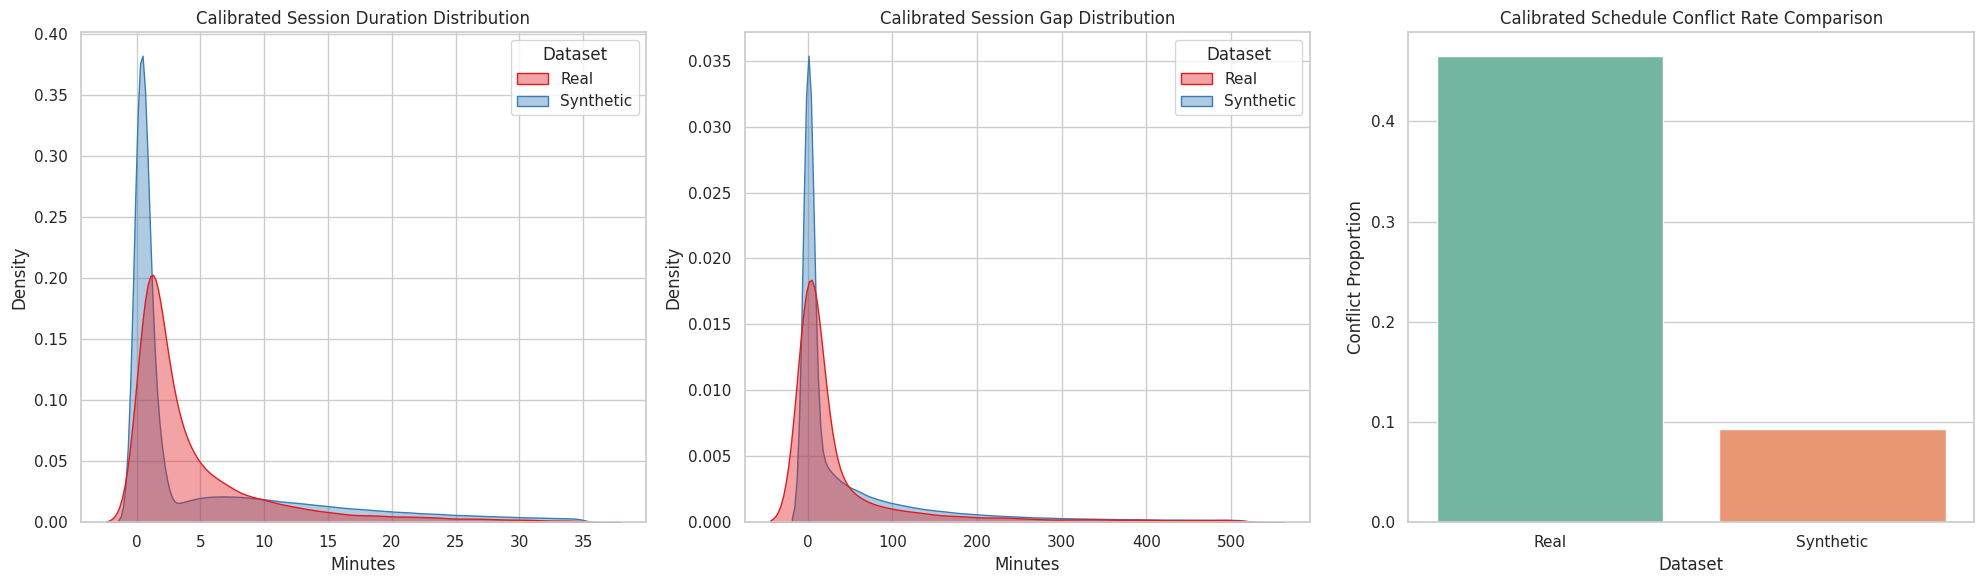

In [ ]:
# Re-run the comparison statistical summary and update the visualizations using the correct 'sessions' variable
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

real_clean = sessions.copy()  # Use sessions instead of df for session-level variables
synth_clean = data.copy()  # Newly generated synthetic dataset

# Standardize fields
real_metrics = pd.DataFrame({
    'Dataset': 'Real',
    'Session_Duration': pd.to_numeric(real_clean['duration_minutes'], errors='coerce'),
    'Session_Gap': pd.to_numeric(real_clean['minutes_since_last_session'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(real_clean['schedule_conflict'], errors='coerce')
})

synth_metrics = pd.DataFrame({
    'Dataset': 'Synthetic',
    'Session_Duration': pd.to_numeric(synth_clean['elapsedDuration'], errors='coerce'),
    'Session_Gap': pd.to_numeric(synth_clean['previousSessionGap'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(synth_clean['scheduleConflict'], errors='coerce')
})

combined_metrics = pd.concat([real_metrics, synth_metrics], ignore_index=True)

print("=== UPDATED STATISTICAL COMPARISON TABLE ===")
stats_summary = combined_metrics.groupby('Dataset').agg({
    'Session_Duration': ['mean', 'median', 'std', 'max'],
    'Session_Gap': ['mean', 'median', 'std'],
    'Schedule_Conflict': ['mean']
}).round(2)
display(stats_summary)

# Updated Plotting
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot A: Session Duration
max_val_dur = combined_metrics['Session_Duration'].quantile(0.95)
sns.kdeplot(ax=axes[0], data=combined_metrics[combined_metrics['Session_Duration'] <= max_val_dur],
            x='Session_Duration', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[0].set_title('Calibrated Session Duration Distribution')
axes[0].set_xlabel('Minutes')

# Plot B: Session Gap
max_val_gap = combined_metrics['Session_Gap'].quantile(0.95)
sns.kdeplot(ax=axes[1], data=combined_metrics[combined_metrics['Session_Gap'] <= max_val_gap],
            x='Session_Gap', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[1].set_title('Calibrated Session Gap Distribution')
axes[1].set_xlabel('Minutes')

# Plot C: Schedule Conflict Rate
sns.barplot(ax=axes[2], data=combined_metrics, x='Dataset', y='Schedule_Conflict', hue='Dataset', palette='Set2', legend=False, errorbar=None)
axes[2].set_title('Calibrated Schedule Conflict Rate Comparison')
axes[2].set_ylabel('Conflict Proportion')

plt.tight_layout()
plt.show()

=== STATISTICAL COMPARISON TABLE ===


Session_Duration               Session_Gap                  \
                      mean median    std        mean median      std   
Dataset                                                                
Real                  5.85   2.23  12.23      194.81   4.50  2227.56   
Synthetic             7.53   1.00  12.51       98.73   3.86   244.00   

          Schedule_Conflict  
                       mean  
Dataset                      
Real                   0.47  
Synthetic              0.09

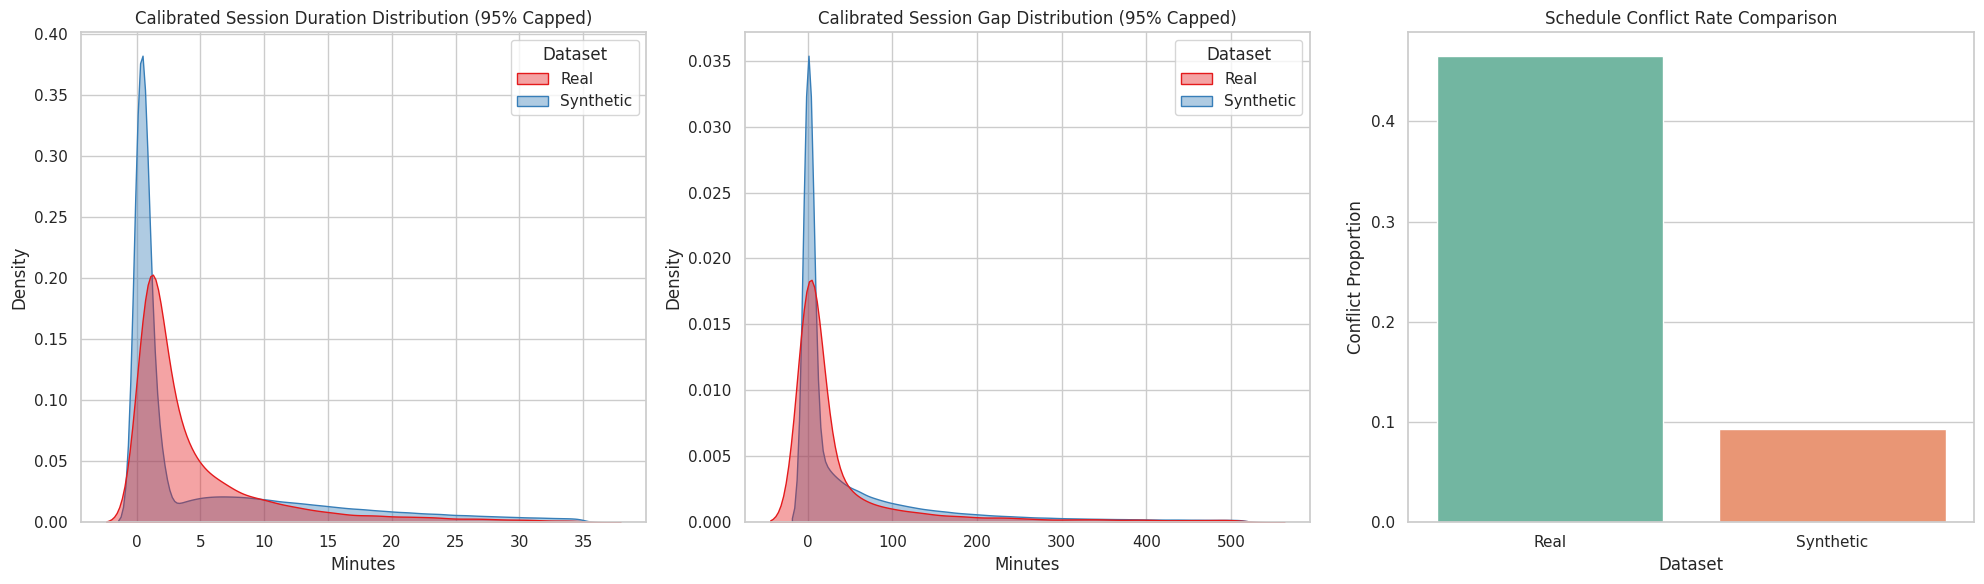

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare datasets
real_clean = sessions.copy()
synth_clean = data.copy()

real_metrics = pd.DataFrame({
    'Dataset': 'Real',
    'Session_Duration': pd.to_numeric(real_clean['duration_minutes'], errors='coerce'),
    'Session_Gap': pd.to_numeric(real_clean['minutes_since_last_session'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(real_clean['schedule_conflict'], errors='coerce')
})

synth_metrics = pd.DataFrame({
    'Dataset': 'Synthetic',
    'Session_Duration': pd.to_numeric(synth_clean['elapsedDuration'], errors='coerce'),
    'Session_Gap': pd.to_numeric(synth_clean['previousSessionGap'], errors='coerce'),
    'Schedule_Conflict': pd.to_numeric(synth_clean['scheduleConflict'], errors='coerce')
})

combined_metrics = pd.concat([real_metrics, synth_metrics], ignore_index=True)

print("=== STATISTICAL COMPARISON TABLE ===")
stats_summary = combined_metrics.groupby('Dataset').agg({
    'Session_Duration': ['mean', 'median', 'std'],
    'Session_Gap': ['mean', 'median', 'std'],
    'Schedule_Conflict': ['mean']
}).round(2)
display(stats_summary)

# Visualization
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot A: Session Duration
max_val_dur = combined_metrics['Session_Duration'].quantile(0.95)
sns.kdeplot(ax=axes[0], data=combined_metrics[combined_metrics['Session_Duration'] <= max_val_dur],
            x='Session_Duration', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[0].set_title('Calibrated Session Duration Distribution (95% Capped)')
axes[0].set_xlabel('Minutes')

# Plot B: Session Gap
max_val_gap = combined_metrics['Session_Gap'].quantile(0.95)
sns.kdeplot(ax=axes[1], data=combined_metrics[combined_metrics['Session_Gap'] <= max_val_gap],
            x='Session_Gap', hue='Dataset', fill=True, common_norm=False, palette='Set1', alpha=0.4)
axes[1].set_title('Calibrated Session Gap Distribution (95% Capped)')
axes[1].set_xlabel('Minutes')

# Plot C: Schedule Conflict Rate Comparison
sns.barplot(ax=axes[2], data=combined_metrics, x='Dataset', y='Schedule_Conflict', hue='Dataset', palette='Set2', legend=False, errorbar=None)
axes[2].set_title('Schedule Conflict Rate Comparison')
axes[2].set_ylabel('Conflict Proportion')

plt.tight_layout()
plt.show()

In [ ]:
# Aggregate session records into daily activity
daily_data = (
    data.groupby(["anonymousUserId", "date"])
    .agg(
        dailyDuration=("elapsedDuration", "sum"),
        dailySessions=("id", "count")
    )
    .reset_index()
)

# Generate the complete date range
all_dates = pd.date_range(
    data["date"].min(),
    data["date"].max(),
    freq="D"
).date

# Create every user-date combination
all_user_dates = pd.MultiIndex.from_product(
    [
        data["anonymousUserId"].unique(),
        all_dates
    ],
    names=["anonymousUserId", "date"]
)

# Reindex to include days with zero sessions
complete_daily = (
    daily_data
    .set_index(["anonymousUserId", "date"])
    .reindex(all_user_dates, fill_value=0)
    .reset_index()
)

print("Daily records:", len(complete_daily))
print("Expected daily records:", 1000 * len(all_dates))

display(complete_daily.head(10))

Daily records: 85000
Expected daily records: 85000


,anonymousUserId,date,dailyDuration,dailySessions
0,syn_0000,2026-06-01,46.768583,11
1,syn_0000,2026-06-02,202.283100,14
2,syn_0000,2026-06-03,219.446933,23
3,syn_0000,2026-06-04,49.667917,11
4,syn_0000,2026-06-05,20.178533,9
5,syn_0000,2026-06-06,85.366633,18
6,syn_0000,2026-06-07,88.469567,13
7,syn_0000,2026-06-08,222.209800,18
8,syn_0000,2026-06-09,74.902483,12
9,syn_0000,2026-06-10,227.781733,35


Generate behavioural features

In [ ]:
# Daily behavioural features
daily_features = (
    complete_daily.groupby("anonymousUserId")
    .agg(
        avg_daily_duration=("dailyDuration", "mean"),
        max_daily_duration=("dailyDuration", "max"),
        std_daily_duration=("dailyDuration", "std"),

        avg_daily_sessions=("dailySessions", "mean"),
        max_daily_sessions=("dailySessions", "max"),
        std_daily_sessions=("dailySessions", "std"),

        active_days=(
            "dailySessions",
            lambda x: (x > 0).sum()
        )
    )
)

# Session-level behavioural features
session_features = (
    data.groupby("anonymousUserId")
    .agg(
        total_sessions=("id", "count"),

        avg_session_duration=("elapsedDuration", "mean"),
        median_session_duration=("elapsedDuration", "median"),
        std_session_duration=("elapsedDuration", "std"),

        avg_session_gap=("previousSessionGap", "mean"),
        avg_sessions_recorded=("sessionsToday", "mean"),

        schedule_conflict_rate=("scheduleConflict", "mean"),
        morning_usage_rate=("morningSocialMedia", "mean"),
        bedtime_usage_rate=("bedtimeSocialMedia", "mean"),

        avg_minutes_since_wake=("minutesSinceWake", "mean"),
        avg_minutes_until_sleep=("minutesUntilSleep", "mean"),

        avg_baseline_duration_ratio=("baselineDurationRatio", "mean"),
        avg_baseline_frequency_ratio=("baselineFrequencyRatio", "mean"),

        unique_apps=("packageName", "nunique")
    )
)

print("Daily features:", daily_features.shape)
print("Session features:", session_features.shape)

Daily features: (1000, 7)
Session features: (1000, 14)


Add Behavioural trend features

In [ ]:
# Ensure chronological ordering
complete_daily["date"] = pd.to_datetime(
    complete_daily["date"]
)

complete_daily = complete_daily.sort_values(
    ["anonymousUserId", "date"]
)

def calculate_trends(group):

    group = group.reset_index(drop=True)

    first_two_weeks = group.iloc[:14]
    last_two_weeks = group.iloc[-14:]

    early_duration = first_two_weeks["dailyDuration"].mean()
    late_duration = last_two_weeks["dailyDuration"].mean()

    early_sessions = first_two_weeks["dailySessions"].mean()
    late_sessions = last_two_weeks["dailySessions"].mean()

    return pd.Series({

        "early_avg_duration": early_duration,
        "late_avg_duration": late_duration,

        "early_avg_sessions": early_sessions,
        "late_avg_sessions": late_sessions,

        "duration_change": late_duration - early_duration,
        "session_change": late_sessions - early_sessions,

        "weekly_duration_variability":
            group["dailyDuration"].std(),

        "weekly_session_variability":
            group["dailySessions"].std()
    })


trend_features = (
    complete_daily
    .groupby("anonymousUserId")
    .apply(calculate_trends)
)

print("Trend features:", trend_features.shape)

display(trend_features.head())

Trend features: (1000, 8)


/tmp/ipykernel_1752/2296960408.py:45: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_trends)


,early_avg_duration,late_avg_duration,early_avg_sessions,late_avg_sessions,duration_change,session_change,weekly_duration_variability,weekly_session_variability
anonymousUserId,,,,,,,,
syn_0000,110.206740,113.053081,14.785714,15.857143,2.846340,1.071429,96.757076,9.169276
syn_0001,167.855864,85.504961,24.642857,12.857143,-82.350904,-11.785714,87.575142,9.894500
syn_0002,336.943132,423.599796,35.428571,49.357143,86.656664,13.928571,260.082676,20.478095
syn_0003,56.835219,42.066213,7.785714,7.214286,-14.769006,-0.571429,42.814337,4.229415
syn_0004,32.788608,29.533771,4.500000,3.214286,-3.254837,-1.285714,25.892585,1.965173


Combine all features and create the classification target
We now combine our three feature groups:
1. Daily behavioural features.
2. Session-level behavioural features.
3. Behavioural trend features.

In [ ]:
# Combine all feature groups
user_features = (
    daily_features
    .join(session_features)
    .join(trend_features)
)

# Create one BSMAS band per user
user_labels = (
    data.groupby("anonymousUserId")["bsmasBand"]
    .first()
)

# Convert three BSMAS categories into two risk classes
user_labels = user_labels.map({
    "LOWER": 0,
    "MODERATE": 0,
    "ELEVATED": 1
})

user_labels.name = "riskLabel"

# Combine features and target
model_data = user_features.join(user_labels).reset_index()

# Handle any missing numerical values
model_data = model_data.fillna(0)

print("Final dataset shape:", model_data.shape)
print("Number of users:", model_data["anonymousUserId"].nunique())

print("\nRisk class distribution:")
print(model_data["riskLabel"].value_counts())

print("\nRisk class percentages:")
print(
    model_data["riskLabel"]
    .value_counts(normalize=True).mul(100).round(2)
)

display(model_data.head())

Final dataset shape: (1000, 31)
Number of users: 1000

Risk class distribution:
riskLabel
0    696
1    304
Name: count, dtype: int64

Risk class percentages:
riskLabel
0    69.6
1    30.4
Name: proportion, dtype: float64


,anonymousUserId,avg_daily_duration,max_daily_duration,std_daily_duration,avg_daily_sessions,max_daily_sessions,std_daily_sessions,active_days,total_sessions,avg_session_duration,...,unique_apps,early_avg_duration,late_avg_duration,early_avg_sessions,late_avg_sessions,duration_change,session_change,weekly_duration_variability,weekly_session_variability,riskLabel
0,syn_0000,115.734033,450.905000,96.757076,15.823529,44,9.169276,79,1345,7.314047,...,5,110.206740,113.053081,14.785714,15.857143,2.846340,1.071429,96.757076,9.169276,0
1,syn_0001,90.833036,549.070233,87.575142,15.364706,59,9.894500,78,1306,5.911798,...,5,167.855864,85.504961,24.642857,12.857143,-82.350904,-11.785714,87.575142,9.894500,0
2,syn_0002,410.934657,1453.377433,260.082676,45.200000,121,20.478095,83,3842,9.091475,...,5,336.943132,423.599796,35.428571,49.357143,86.656664,13.928571,260.082676,20.478095,1
3,syn_0003,39.102100,203.795300,42.814337,6.411765,20,4.229415,81,545,6.098493,...,5,56.835219,42.066213,7.785714,7.214286,-14.769006,-0.571429,42.814337,4.229415,0
4,syn_0004,23.336873,121.522533,25.892585,3.400000,10,1.965173,81,289,6.863786,...,5,32.788608,29.533771,4.500000,3.214286,-3.254837,-1.285714,25.892585,1.965173,0


In [ ]:
# Check for missing values
print("Missing values:")
print(model_data.isnull().sum().sum())

# Check for duplicate users
print("\nDuplicate user IDs:")
print(model_data["anonymousUserId"].duplicated().sum())

# Check the target distribution
print("\nTarget distribution:")
print(model_data["riskLabel"].value_counts())

# Check feature count
print("\nNumber of input features:",
      len(model_data.columns) - 2)

Missing values:
0

Duplicate user IDs:
0

Target distribution:
riskLabel
0    696
1    304
Name: count, dtype: int64

Number of input features: 29


Now we train the dataset

In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = model_data.drop(
    columns=["anonymousUserId", "riskLabel"]
)

y = model_data["riskLabel"]

# First split: 80% development, 20% final testing
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=42,
    stratify=y_dev
)

print("Training users:", len(X_train))
print("Validation users:", len(X_val))
print("Testing users:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training users: 640
Validation users: 160
Testing users: 200

Training class distribution:
riskLabel
0    446
1    194
Name: count, dtype: int64

Validation class distribution:
riskLabel
0    111
1     49
Name: count, dtype: int64

Testing class distribution:
riskLabel
0    139
1     61
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {

    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    ),

    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_split=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingClassifier(
            max_iter=200,
            learning_rate=0.08,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

results = []

for name, model in models.items():

    # Train using training data only
    model.fit(X_train, y_train)

    # Predict validation data
    predictions = model.predict(X_val)

    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,0.831,0.789,0.612,0.690,0.842
1,Logistic Regression,0.750,0.571,0.735,0.643,0.822
3,Gradient Boosting,0.788,0.692,0.551,0.614,0.815
0,Dummy Baseline,0.694,0.000,0.000,0.000,0.500


Tune classification threshholds for best model

In [ ]:
# Select the best non-baseline model
best_name = (
    results_df[
        results_df["Model"] != "Dummy Baseline"
    ].iloc[0]["Model"]
)

best_model = models[best_name]

# Obtain predicted probabilities
val_probabilities = best_model.predict_proba(X_val)[:, 1]

print("Selected model:", best_name)

Selected model: Random Forest


Then now we test different models

In [ ]:
threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.05):

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),

        "Accuracy": accuracy_score(
            y_val, predictions
        ),

        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),

        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))

,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.20,0.625,0.444,0.898,0.595
1,0.25,0.700,0.506,0.837,0.631
2,0.30,0.731,0.545,0.735,0.626
3,0.35,0.769,0.607,0.694,0.648
4,0.40,0.806,0.688,0.673,0.680
5,0.45,0.806,0.714,0.612,0.659
6,0.50,0.831,0.789,0.612,0.690
7,0.55,0.819,0.778,0.571,0.659
8,0.60,0.806,0.800,0.490,0.608
9,0.65,0.788,0.778,0.429,0.553


In [ ]:
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax(),
    "Threshold"
]

print("Selected threshold:", best_threshold)

Selected threshold: 0.5


Evaluate model on unseen users

Final model: Random Forest
Decision threshold: 0.5

Classification Report:
              precision    recall  f1-score   support

      NORMAL       0.81      0.91      0.86       139
    ELEVATED       0.73      0.52      0.61        61

    accuracy                           0.80       200
   macro avg       0.77      0.72      0.74       200
weighted avg       0.79      0.80      0.78       200


Confusion Matrix:


,Predicted NORMAL,Predicted ELEVATED
Actual NORMAL,127,12
Actual ELEVATED,29,32


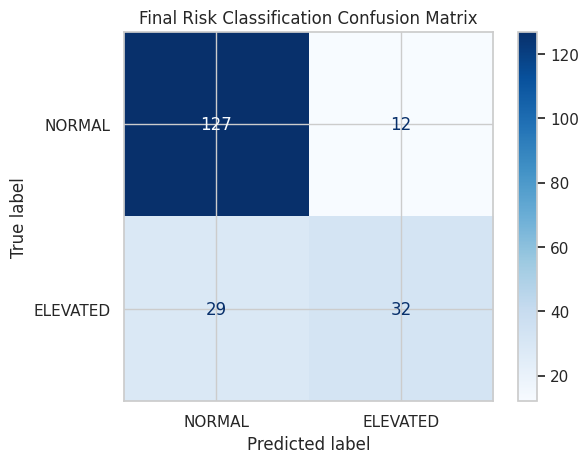

Test ROC AUC: 0.846


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Get probabilities for unseen test users
test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Final model:", best_name)
print("Decision threshold:", best_threshold)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["NORMAL", "ELEVATED"]
    )
)

print("\nConfusion Matrix:")

cm = confusion_matrix(y_test, test_predictions)

display(pd.DataFrame(
    cm,
    index=["Actual NORMAL", "Actual ELEVATED"],
    columns=["Predicted NORMAL", "Predicted ELEVATED"]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "ELEVATED"]
).plot(cmap="Blues")

plt.title("Final Risk Classification Confusion Matrix")
plt.show()

print(
    "Test ROC AUC:",
    round(
        roc_auc_score(y_test, test_probabilities),
        3
    )
)

In [ ]:
import json
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Combine training and validation data
X_final = pd.concat([X_train, X_val])
y_final = pd.concat([y_train, y_val])

# Create the final Logistic Regression pipeline
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Train final model on 800 users
final_model.fit(X_final, y_final)

# Evaluate on the untouched test users
test_probabilities = final_model.predict_proba(X_test)[:, 1]

threshold = 0.40

test_predictions = (
    test_probabilities >= threshold
).astype(int)

print("Final model evaluation")
print("Accuracy:", accuracy_score(y_test, test_predictions))
print("Precision:", precision_score(y_test, test_predictions))
print("Recall:", recall_score(y_test, test_predictions))
print("F1-score:", f1_score(y_test, test_predictions))
print("ROC AUC:", roc_auc_score(y_test, test_probabilities))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["NORMAL", "ELEVATED"]
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))

Final model evaluation
Accuracy: 0.725
Precision: 0.53125
Recall: 0.8360655737704918
F1-score: 0.6496815286624203
ROC AUC: 0.8501002476707159

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.90      0.68      0.77       139
    ELEVATED       0.53      0.84      0.65        61

    accuracy                           0.72       200
   macro avg       0.72      0.76      0.71       200
weighted avg       0.79      0.72      0.74       200


Confusion matrix:
[[94 45]
 [10 51]]


In [ ]:
import json

# Extract the trained pipeline components
imputer = final_model.named_steps["imputer"]
scaler = final_model.named_steps["scaler"]
classifier = final_model.named_steps["model"]

# Prepare model parameters
model_parameters = {

    "model_type": "Logistic Regression",

    "threshold": 0.40,

    "feature_names": list(X_final.columns),

    "imputation_values": imputer.statistics_.tolist(),

    "scaler_means": scaler.mean_.tolist(),

    "scaler_scales": scaler.scale_.tolist(),

    "coefficients": classifier.coef_[0].tolist(),

    "intercept": float(classifier.intercept_[0])
}

# Save parameters as JSON
with open("risk_model_parameters.json", "w") as file:
    json.dump(model_parameters, file, indent=4)

print("Model parameters exported successfully!")

print("Number of features:",
      len(model_parameters["feature_names"]))

print("Threshold:",
      model_parameters["threshold"])

Model parameters exported successfully!
Number of features: 29
Threshold: 0.4


In [ ]:
!pip install shap

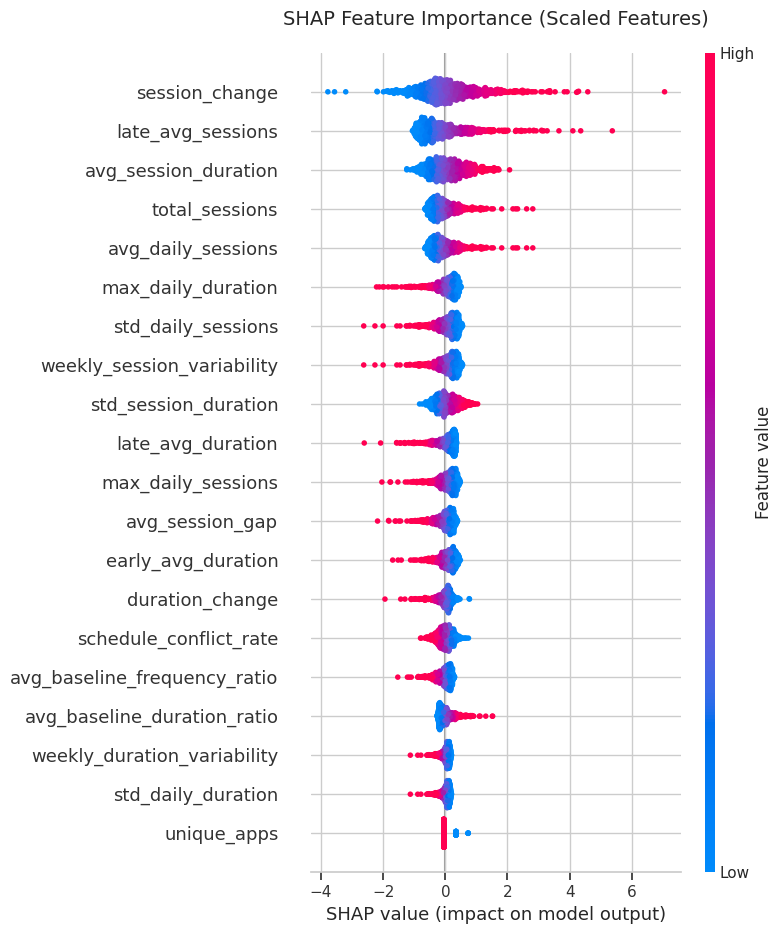

In [ ]:
import shap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Extract preprocessing steps from the final pipeline
preprocessor = Pipeline([
    ("imputer", final_model.named_steps["imputer"]),
    ("scaler", final_model.named_steps["scaler"])
])

# Transform development features into scaled representation
X_final_scaled = preprocessor.transform(X_final)
X_final_scaled_df = pd.DataFrame(X_final_scaled, columns=X_final.columns)

# Set up SHAP Explainer using the logistic regression model parameters
classifier_step = final_model.named_steps["model"]
explainer = shap.LinearExplainer(classifier_step, X_final_scaled_df)
shap_values = explainer(X_final_scaled_df)

# Plot summary
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_final_scaled_df, show=False)
plt.title("SHAP Feature Importance (Scaled Features)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()